## Module 4 Homework (2026 Cohort)

In this homework, you are required to understand how the system works as a whole, adjust the code accordingly, and interpret the results correctly. The task involves modifying a few lines of code and run the whole notebook to check the results.

Please use the new workbook [[2026]_Module_04_Colab_Trading_Simulations.ipynb](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/04-trading-strategy-and-simulation/%5B2026%5D_Module_04_Colab_Trading_Simulations.ipynb) for all tasks. This workbook contains a clean version of the code, with hyperparameter tuning commented out and the best models hard-coded. It should take a few minutes to run on Google Colab. Before solving the problems, make sure you can run the workbook *"as is"*.

**IMPORTANT**: Every time you start a new problem, **make a fresh copy** of the notebook and start from scratch. Do **not** apply edits from previous tasks to the same notebook instance.

**HINT**: To avoid data truncation in GitHub’s UI, try one of the following:
* Open the notebook in [Colab using the GitHub link](https://colab.research.google.com/github/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/04-trading-strategy-and-simulation/%5B2026%5D_Module_04_Colab_Trading_Simulations.ipynb).
* Clone the repository locally and open the notebook in Jupyter Notebook.

### Question 1: Less Features is More 

**Find the CAGR for the pred10_rf_best_rule_55	using the new setup (with fewer dummy variables).**


**The idea**: Reducing the number of features can help models perform better. As seen in the lecture, some models (e.g., Logistic Regression, Deep Neural Networks) may underperform due to too many features—especially the numerous dummy variables from exercises and individual stock tickers.

1) **Redefine the "CATEGORICAL" set.** 
Remove `ticker` and `month_wom` from the `CATEGORICAL` list *just* before you generate dummies ising the `pd.get_dummies()` function. To check yourself: `df_with_dummies[NUMERICAL+DUMMIES].info()` in the original setup should give 301 features. In the new setup, `df_with_dummies[NUMERICAL+DUMMIES].info()` should show 208 features (about 31% fewer).

2) **Run the entire notebook.** 
At the end of the notebook (after the bubble chart), check the CAGR for `pred10_rf_best_rule_55` (the best ML predictor has changed). Expected result: The new CAGR should be *slightly higher* than the original one, which was 1.1195.

**Answer**: 1.128

### Question 2: Most Efficient Random Forest Decision Rule

**What is the probability threshold for the second-best Random Forest decision rule, if you want to have the number of average trades per day BELOW 5?**


#### **The Idea**

The goal is to learn how to construct and interpret the `tpr_dataframe` for another model—**Random Forest**—and connect it with financial performance.

In this task, you'll define new predictors using custom probability thresholds ranging from **0.56 to 0.64**, thereby covering the full interval from **0.55 to 0.65** (two threshold-based predictors are already defined, including `pred10_rf_best_rule_55` — the estimator found in Question 1 that works better than the other rules). The objective is to build a dataframe with these decision rules, following the expected pattern:

- **Higher thresholds → Higher precision**
- **Higher thresholds → Fewer total trades**

However, now you're optimizing not just for ML performance (like precision), but also for **financial results (CAGR)** and **time efficiency (average trades per day)**. These relationships aren’t always straightforward, so experimentation is key.



### Steps

0. Make **a fresh copy** of the notebook **from Question 1** (the one with the shortened dummy-variable setup, where the Random Forest with `max_depth=13` and `n_estimators=100` is used). Reuse that notebook as your starting point instead of the original Module 04 notebook — you'll be adding more rules on top of the same model, just with different thresholds.

1. **Construct the `tpr_fpr_dataframe` for the Random Forest classifier**

   - In your code:
     ```python
     # Comment out
     y_pred_test = clf_best.predict_proba(X_test)
     # Uncomment
     y_pred_test = rf_best.predict_proba(X_test)
     ```
   - The Random Forest model provides a smoother prediction probability distribution  
     *(see density plot using `sns.histplot(y_pred_test_class1)`)*.
   - The `df_scores` dataframe will now reflect Random Forest statistics.
   - Watch how **TP + FP (total trades)** decreases with higher thresholds.
   - Examine **precision and recall** at various thresholds:
     - Precision increases with higher thresholds.
     - Recall and total trades decrease.
   - ⚠️ *But beware: higher precision and fewer trades do not always result in better financial returns (CAGR).*

2. **Define new prediction columns for thresholds 0.56 to 0.64**

   Add predictors to cover the full threshold range:
   - Use names like (where xx and yy and parameters):  
     `new[predxx_rf_best_rule_yy] =  (y_pred_all_class1_array >= 0.yy).astype(int)`  

   - Continue after existing ones:  
     `new_df['pred10_rf_best_rule_55'] = (y_pred_all_class1_array >= 0.55).astype(int)`  
     `new_df['pred11_rf_best_rule_65'] = (y_pred_all_class1_array >= 0.65).astype(int)`

3. **Review the simulation results in `df_sim1_results`**

   - Our current best rule, `pred10_rf_best_rule_55`, delivers a good CAGR but trades slightly **more than 5 times per day on average**. Among the new thresholds you've defined, find the one where **avg. daily investments < 5**, while still achieving the best CAGR possible (close to 1.12) at that trade-off.
   - It's likely that this rule won't beat `pred10_rf_best_rule_55` on CAGR — only on trade efficiency (fewer trades per day). That's fine: we'll call this the **second-best model**, since it's the best one specifically within the "fewer than 5 trades per day" subspace.
   - Write down the decision rule threshold of this second-best model.

**Answer**: 0.57  
Avg. trades per day: 4.851163  
Precision: 0.63

### Question 3: Redefining the Growth Target

**What is the number of trades for the best predictor `pred5_clf_10` (after redefining the target variable)?**

Your goal is to adjust how we define the positive-growth target and examine how it affects model performance.

0. Make **a fresh copy** of the Module 04 notebook.

1. Look at the distribution of `growth_future_30d` and `is_positive_growth_30d_future`. You’ll see that the median for  `growth_future_30d` is around 1.021 (2.1%), and the top 25% starts at about 1.085 (8.5%). The current version of `is_positive_growth_30d_future` has about 60% of records labeled as class 1 (when defined as 1 when `growth_future_30d`>1)

2. Redefine `is_positive_growth_30d_future` to equal 1, if `growth_future_30d > 1.022`; otherwise, 0. This definition will be used for all future predictions. With this new version, only about 50% of records will be labeled as class 1 (down from 60%).

3. Run the notebook again using this revised target. Threshold-based rules may not perform as well, so check which predictor now delivers the best financial result (CAGR)—it is likely to be  `pred5_clf_10`. It will have a similar CAGR, but fewer trades per day, since we're now targeting predicted growth above 2.2% instead of above 0%.

**Write down the number of trades for the best predictor `pred5_clf_10`**

**Answer**: 8

### Question 4:  [EXPLORATORY] Describe Your Ideal Trading Strategy
**Briefly describe your ideal strategy**

So far, we’ve only used one simple rule: “Invest $100 in each positive prediction.” Now it’s your turn to design a better strategy.

Use what you’ve learned and be creative. You can use predictions from one model or combine predictions from several models or different thresholds from the same model.

For example, you might say: *“Take the 3 best predictions with a threshold above 0.7 and invest all my available money equally in them.”*

Think about how you would decide which predictions to use, how much to invest, how to reduce the number of trades, and how to manage risk.

Write a few clear sentences describing your strategy and how you would implement it.

> **Fresh copy of week 4 colab code below**
>
> **Goal:** Modify the code to answer the homework"*

# Imports and Installs

In [1]:
# IMPORTS
import numpy as np
import pandas as pd

#Fin Data Sources
import yfinance as yf
# import pandas_datareader as pdr

#Data viz
import plotly.graph_objs as go
import plotly.graph_objects as go
import plotly.express as px

import time
from datetime import date

# for graphs
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Imports form ML (Decision Trees)
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

# Disable SettingWithCopyWarning
pd.options.mode.chained_assignment = None  # default='warn'

# 0) One DataFrame with Dummies
* including newly defined "month-week_of_month"

## 0.1) Read and truncate data (last 25 years from 2000), define variable sets




In [3]:
# full dataset for 33 stocks
df_full = pd.read_parquet("../documents/week04/stocks_df_combined_2026_09_18.parquet.brotli", )

# Q3: positive growth now means more than 2.2% in 30 days (was: more than 0%)
df_full['is_positive_growth_30d_future'] = (df_full['growth_future_30d'] > 1.022).astype(int)

In [4]:
df_full.info()

<class 'pandas.DataFrame'>
Index: 240759 entries, 0 to 6018
Columns: 203 entries, Open to growth_btc_usd_365d
dtypes: datetime64[ns](3), float64(129), int32(64), int64(5), str(2)
memory usage: 317.7 MB


In [5]:
# growth indicators (but not future growth)
GROWTH = [g for g in df_full.keys() if (g.find('growth_')==0)&(g.find('future')<0)]
GROWTH

['growth_1d',
 'growth_3d',
 'growth_7d',
 'growth_30d',
 'growth_90d',
 'growth_365d',
 'growth_dax_1d',
 'growth_dax_3d',
 'growth_dax_7d',
 'growth_dax_30d',
 'growth_dax_90d',
 'growth_dax_365d',
 'growth_snp500_1d',
 'growth_snp500_3d',
 'growth_snp500_7d',
 'growth_snp500_30d',
 'growth_snp500_90d',
 'growth_snp500_365d',
 'growth_dji_1d',
 'growth_dji_3d',
 'growth_dji_7d',
 'growth_dji_30d',
 'growth_dji_90d',
 'growth_dji_365d',
 'growth_epi_1d',
 'growth_epi_3d',
 'growth_epi_7d',
 'growth_epi_30d',
 'growth_epi_90d',
 'growth_epi_365d',
 'growth_gold_1d',
 'growth_gold_3d',
 'growth_gold_7d',
 'growth_gold_30d',
 'growth_gold_90d',
 'growth_gold_365d',
 'growth_wti_oil_1d',
 'growth_wti_oil_3d',
 'growth_wti_oil_7d',
 'growth_wti_oil_30d',
 'growth_wti_oil_90d',
 'growth_wti_oil_365d',
 'growth_brent_oil_1d',
 'growth_brent_oil_3d',
 'growth_brent_oil_7d',
 'growth_brent_oil_30d',
 'growth_brent_oil_90d',
 'growth_brent_oil_365d',
 'growth_btc_usd_1d',
 'growth_btc_usd_3d',


In [6]:
df_full.keys()

Index(['Open', 'High', 'Low', 'Close_x', 'Volume', 'Dividends', 'Stock Splits',
       'Ticker', 'Year', 'Month',
       ...
       'growth_brent_oil_7d', 'growth_brent_oil_30d', 'growth_brent_oil_90d',
       'growth_brent_oil_365d', 'growth_btc_usd_1d', 'growth_btc_usd_3d',
       'growth_btc_usd_7d', 'growth_btc_usd_30d', 'growth_btc_usd_90d',
       'growth_btc_usd_365d'],
      dtype='str', length=203)

In [7]:
# leaving only Volume ==> generate ln(Volume)
OHLCV = ['Open','High','Low','Close_x','Volume']

In [8]:
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type']

In [9]:
TO_PREDICT = [g for g in df_full.keys() if (g.find('future')>=0)]
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [10]:
# we define dummy variables on Dividends and Stock Splits events later, but drop the original abs. values
TO_DROP = ['Year','Date','index_x', 'index_y', 'index', 'Quarter','Close_y','Dividends','Stock Splits'] + CATEGORICAL + OHLCV
TO_DROP

['Year',
 'Date',
 'index_x',
 'index_y',
 'index',
 'Quarter',
 'Close_y',
 'Dividends',
 'Stock Splits',
 'Month',
 'Weekday',
 'Ticker',
 'ticker_type',
 'Open',
 'High',
 'Low',
 'Close_x',
 'Volume']

In [11]:
# let's define on more custom numerical features
# Add a small constant to avoid log(0)
df_full['ln_volume'] = df_full.Volume.apply(lambda x: np.log(x+ 1e-6))

In [12]:
# define columns on Dividends or Stock Splits
df_full['div_payout'] = (df_full.Dividends>0).astype(int)
df_full['stock_split'] = (df_full['Stock Splits']>0).astype(int)

In [13]:
# manually defined features
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative','volatility', 'ln_volume','div_payout','stock_split']

In [14]:
# All Supported Ta-lib indicators: https://github.com/TA-Lib/ta-lib-python/blob/master/docs/funcs.md

TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1','aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo','dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

In [15]:
TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl')>=0]
print(f'Technical patterns count = {len(TECHNICAL_PATTERNS)}, examples = {TECHNICAL_PATTERNS[0:5]}')

Technical patterns count = 61, examples = ['cdl2crows', 'cdl3blackrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside']


In [16]:
MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
 'DGS1', 'DGS5', 'DGS10']

In [17]:
NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

In [18]:
# CHECK: NO OTHER INDICATORS LEFT
OTHER = [k for k in df_full.keys() if k not in OHLCV + CATEGORICAL + NUMERICAL + TO_DROP + TO_PREDICT]
OTHER

[]

In [19]:
df_full.Ticker.nunique()

33

In [20]:
# truncated df_full with 25 years of data (and defined growth variables)
df = df_full[df_full.Date>='2000-01-01']
df.info()

<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 206 entries, Open to stock_split
dtypes: datetime64[ns](3), float64(130), int32(64), int64(7), str(2)
memory usage: 271.7 MB


In [21]:
# tickers, min-max date, count of daily observations
df.groupby(['Ticker'])['Date'].agg(['min','max','count'])

,min,max,count
Ticker,,,
AAPL,2000-01-03,2026-09-18,6718
ACN,2001-07-19,2026-09-18,6329
AMZN,2000-01-03,2026-09-18,6718
ASML,2000-01-03,2026-09-18,6718
AVGO,2009-08-06,2026-09-18,4306
BHARTIARTL.NS,2002-07-01,2026-09-18,6016
BRK-B,2000-01-03,2026-09-18,6718
CDI.PA,2000-01-03,2026-09-18,6863
GOOG,2004-08-19,2026-09-18,5556


## 0.2) Dummies

In [22]:
# what are the categorical features?
CATEGORICAL

['Month', 'Weekday', 'Ticker', 'ticker_type']

In [23]:
# dummy variables are not generated from Date and numeric variables

# df.loc[:,'Month'] = df['Month'].dt.strftime('%B').astype('string')

df['Month'] = df['Month'].dt.strftime('%B')
df['Weekday'] = df['Weekday'].astype('string')
# .astype(str)

### 0.2.1) Create a new string column 'month_wom' (month_week_of_month)

In [24]:
# define week of month (as a string)
df['wom'] = df.Date.apply(lambda d: (d.day-1)//7 + 1).astype(str)

In [25]:
# check values for week-of-month (should be between 1 and 5)
df.wom.value_counts()

wom
2    47550
3    46520
4    46117
1    45860
5    16245
Name: count, dtype: int64

In [26]:
df.loc[:,'month_wom'] = df.Month + '_w' + df.wom

In [27]:
# examples of encoding
df.month_wom.value_counts()[0:2]

month_wom
August_w1    4077
July_w4      4075
Name: count, dtype: int64

In [28]:
# del wom temp variable
del df['wom']

### 0.2.2) Generate all dummies

In [29]:
# what are the categorical features?
CATEGORICAL.append('month_wom')

# Q1: fewer dummies, so drop the ticker and month-week-of-month dummies             ## ADDED
# CATEGORICAL = [c for c in CATEGORICAL if c not in ('Ticker', 'month_wom')]        ## Q3: disabled (Q3 uses the original 301 features)

CATEGORICAL

['Month', 'Weekday', 'Ticker', 'ticker_type', 'month_wom']

In [30]:
# Generate dummy variables (no need for bool, let's have int32 instead)
dummy_variables = pd.get_dummies(df[CATEGORICAL], dtype='int32')

In [31]:
dummy_variables.info()

<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 115 entries, Month_April to month_wom_September_w5
dtypes: int32(115)
memory usage: 90.3 MB


In [32]:
# get dummies names in a list
DUMMIES = dummy_variables.keys().to_list()
DUMMIES

['Month_April',
 'Month_August',
 'Month_December',
 'Month_February',
 'Month_January',
 'Month_July',
 'Month_June',
 'Month_March',
 'Month_May',
 'Month_November',
 'Month_October',
 'Month_September',
 'Weekday_0',
 'Weekday_1',
 'Weekday_2',
 'Weekday_3',
 'Weekday_4',
 'Weekday_5',
 'Weekday_6',
 'Ticker_AAPL',
 'Ticker_ACN',
 'Ticker_AMZN',
 'Ticker_ASML',
 'Ticker_AVGO',
 'Ticker_BHARTIARTL.NS',
 'Ticker_BRK-B',
 'Ticker_CDI.PA',
 'Ticker_GOOG',
 'Ticker_HDB',
 'Ticker_HINDUNILVR.NS',
 'Ticker_IBN',
 'Ticker_IDEXY',
 'Ticker_INFY',
 'Ticker_ITC.NS',
 'Ticker_JPM',
 'Ticker_LICI.NS',
 'Ticker_LLY',
 'Ticker_LT.NS',
 'Ticker_MC.PA',
 'Ticker_META',
 'Ticker_MSFT',
 'Ticker_NVDA',
 'Ticker_NVO',
 'Ticker_OR.PA',
 'Ticker_RELIANCE.NS',
 'Ticker_RMS.PA',
 'Ticker_SAP',
 'Ticker_SBIN.NS',
 'Ticker_SIE.DE',
 'Ticker_TCS.NS',
 'Ticker_TTE',
 'Ticker_V',
 'ticker_type_EU',
 'ticker_type_INDIA',
 'ticker_type_US',
 'month_wom_April_w1',
 'month_wom_April_w2',
 'month_wom_April_w3',
 'mo

In [33]:
len(DUMMIES)

115

In [34]:
# Concatenate the dummy variables with the original DataFrame
df_with_dummies = pd.concat([df, dummy_variables], axis=1)

In [35]:
df_with_dummies[NUMERICAL+DUMMIES].info()

<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 301 entries, growth_1d to month_wom_September_w5
dtypes: float64(121), int32(177), int64(3)
memory usage: 329.5 MB


### 1.2.3) Get correlations for month_wom (month-week_of_month) with is_futur

In [36]:
DUMMIES_MONTH_WOM = [k for k in DUMMIES if k.startswith('month_wom')]
# check a few records
DUMMIES_MONTH_WOM[0:2]

['month_wom_April_w1', 'month_wom_April_w2']

In [37]:
corr_month_wom_vs_is_positive_growth_30d_future = df_with_dummies[DUMMIES_MONTH_WOM+TO_PREDICT].corr()['is_positive_growth_30d_future']

In [38]:
corr_month_wom_vs_is_positive_growth_30d_future

month_wom_April_w1               0.005829
month_wom_April_w2               0.000794
month_wom_April_w3               0.007346
month_wom_April_w4              -0.001307
month_wom_April_w5              -0.003088
                                   ...   
month_wom_September_w3          -0.007491
month_wom_September_w4           0.016366
month_wom_September_w5           0.016165
growth_future_30d                0.707441
is_positive_growth_30d_future    1.000000
Name: is_positive_growth_30d_future, Length: 62, dtype: float64

In [39]:
# create a dataframe for an easy way to sort
corr_month_wom_vs_is_positive_growth_30d_future_df = pd.DataFrame(corr_month_wom_vs_is_positive_growth_30d_future)

In [40]:
# rename column 'is_positive_growth_5d_future' to 'corr'
corr_month_wom_vs_is_positive_growth_30d_future_df.rename(columns={'is_positive_growth_30d_future':'corr'},inplace=True)

In [41]:
corr_month_wom_vs_is_positive_growth_30d_future_df.loc[:, 'abs_corr'] = corr_month_wom_vs_is_positive_growth_30d_future_df['corr'].abs()

In [42]:
corr_month_wom_vs_is_positive_growth_30d_future_df.sort_values(by='abs_corr')

,corr,abs_corr
month_wom_February_w4,-0.000268,0.000268
month_wom_August_w1,-0.000608,0.000608
month_wom_April_w2,0.000794,0.000794
month_wom_March_w5,-0.000896,0.000896
month_wom_July_w1,-0.000987,0.000987
...,...,...
month_wom_January_w4,-0.019286,0.019286
month_wom_February_w2,-0.019605,0.019605
month_wom_October_w4,0.026057,0.026057
growth_future_30d,0.707441,0.707441


In [43]:
# ANSWER Q1 HA3: # TOP CORR NEW DUMMY with is_positive: ANSWER 0.025 (rounded to 3 digits)

### 1.2.4) Temporal split

> **Reading note: Train / Validation / Test split (still part of Section 0)**
>
> `temporal_split` cuts the history **by date**: the oldest ~70% is Train, the next ~15% Validation, the most recent ~15% Test. It's never random, because in real life you always predict the future from the past.
>
> `new_df` is a fresh copy of the finished table. Everything from here on works with `new_df`.

In [44]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    """
    Splits a DataFrame into three buckets based on the temporal order of the 'Date' column.

    Args:
        df (DataFrame): The DataFrame to split.
        min_date (str or Timestamp): Minimum date in the DataFrame.
        max_date (str or Timestamp): Maximum date in the DataFrame.
        train_prop (float): Proportion of data for training set (default: 0.6).
        val_prop (float): Proportion of data for validation set (default: 0.2).
        test_prop (float): Proportion of data for test set (default: 0.2).

    Returns:
        DataFrame: The input DataFrame with a new column 'split' indicating the split for each row.
    """
    # Define the date intervals
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)

    # Assign split labels based on date ranges
    split_labels = []
    for date in df['Date']:
        if date <= train_end:
            split_labels.append('train')
        elif date <= val_end:
            split_labels.append('validation')
        else:
            split_labels.append('test')

    # Add 'split' column to the DataFrame
    df['split'] = split_labels

    return df

In [45]:
min_date_df = df_with_dummies.Date.min()
max_date_df = df_with_dummies.Date.max()

df_with_dummies = temporal_split(df_with_dummies,
                                 min_date = min_date_df,
                                 max_date = max_date_df)

In [46]:
df_with_dummies['split'].value_counts()/len(df_with_dummies)

split
train         0.676458
test          0.163936
validation    0.159606
Name: count, dtype: float64

In [47]:
# remove the "segmentation" problem (warning message on df performance after many joins and data transformations)
new_df = df_with_dummies.copy()

# 1) Modeling

> **Reading note: Section 1 Modeling**
>
> Each approach adds a `pred…` column of 0/1 to `new_df` ("up" / "not up"). They're scored on the **Test** period by **precision**: *of the days we predicted "up", what % actually went up?*
>
> The first cells are sanity checks: the date range of each split and whether growth looks similar across them.

In [48]:
# Full dataframe (transformed and truncated to 25 years)
new_df.info()

<class 'pandas.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 323 entries, Open to split
dtypes: datetime64[ns](2), float64(130), int32(178), int64(7), str(5), string(1)
memory usage: 368.5 MB


In [49]:
# check one record: it has abs. values, text, and numbers
new_df.head(1)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,month_wom_October_w2,month_wom_October_w3,month_wom_October_w4,month_wom_October_w5,month_wom_September_w1,month_wom_September_w2,month_wom_September_w3,month_wom_September_w4,month_wom_September_w5,split
3490,35.623602,36.00298,33.992277,35.377007,53228400.0,0.0,0.0,MSFT,2000,January,...,0,0,0,0,0,0,0,0,0,train


In [50]:
# time split on train/validation/test: FIXED dates of split, approx. 70%, 15%, 15% split
new_df.groupby(['split'])['Date'].agg({'min','max','count'})

,count,min,max
split,,,
test,33163,2022-09-16,2026-09-18
train,136842,2000-01-03,2018-09-13
validation,32287,2018-09-14,2022-09-15


In [51]:
# check for imbalances of growth for train/test/validation
new_df.groupby(by='split')['growth_future_30d'].describe()

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,32173.0,1.024840,0.099602,0.588160,0.963423,1.018612,1.078930,1.648934
train,136842.0,1.023525,0.121019,0.246131,0.960703,1.020272,1.082224,5.179688
validation,32287.0,1.021737,0.106653,0.461847,0.960477,1.024186,1.084679,1.783609


In [52]:
# what do we try to predict
new_df[TO_PREDICT].head(1)

,growth_future_30d,is_positive_growth_30d_future
3490,0.845576,0


In [53]:
# to be used as features
new_df[NUMERICAL+DUMMIES].head(1)

,growth_1d,growth_3d,growth_7d,growth_30d,growth_90d,growth_365d,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,...,month_wom_October_w1,month_wom_October_w2,month_wom_October_w3,month_wom_October_w4,month_wom_October_w5,month_wom_September_w1,month_wom_September_w2,month_wom_September_w3,month_wom_September_w4,month_wom_September_w5
3490,0.998394,0.988341,0.991494,1.372332,1.22295,2.063052,0.970196,0.983855,1.051736,1.134572,...,0,0,0,0,0,0,0,0,0,0


## 1.1) Manual 'rule of thumb' predictions
* (pred0) CCI>200 (binary, on technical indicator CCI)
* (pred1) growth_30d>1
* (pred2) (growth_30d>1) & (growth_snp500_30d>1)
* (pred3) (DGS10 <= 4) & (DGS5 <= 1)
* (pred4) (DGS10 > 4) & (FEDFUNDS <= 4.795)

> **Reading note: 1.1 Hand-written rules (the baseline)**
>
> - `pred0`–`pred2`: same rules as week 3 (CCI > 200, the stock rose over 30 days, the stock and the S&P 500 rose)
> - `pred3`, `pred4`: rules on interest rates from the homework (10-year and 5-year Treasury yields, Fed funds rate)
>
> `get_predictions_correctness` finds every `pred…` column, adds a matching `is_correct_predN` column, and prints precision on Test. It's called again each time a new prediction is added. If a rule never fires on Test (e.g. `pred4`), it has no precision at all.

In [54]:
# generate manual predictions
# Let's label all prediction features with prefix "pred"
new_df['pred0_manual_cci'] = (new_df.cci>200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d>1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)

In [55]:
# new manual predictions from HA
new_df['pred3_manual_dgs10_5'] = ((new_df['DGS10'] <= 4.5) & (new_df['DGS5'] <= 4)).astype(int)
new_df['pred4_manual_dgs10_fedfunds'] = ((new_df['DGS10'] > 4) & (new_df['FEDFUNDS'] <= 4.795)).astype(int)

In [56]:
# sample of 10 observations and predictions
new_df[['cci','growth_30d','growth_snp500_30d','pred0_manual_cci','pred1_manual_prev_g1','pred2_manual_prev_g1_and_snp','pred3_manual_dgs10_5','pred4_manual_dgs10_fedfunds','is_positive_growth_30d_future']].sample(10)

,cci,growth_30d,growth_snp500_30d,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_positive_growth_30d_future
692,90.235986,1.206581,0.980839,0,1,0,0,1,1
2376,-173.528542,0.921409,0.825837,0,0,0,1,0,1
294,-47.398637,0.965892,1.074808,0,0,0,0,1,0
2799,-71.123044,1.016300,1.028857,0,1,1,1,0,0
2523,-48.634685,1.061820,1.036251,0,1,1,1,0,0
7454,-76.113600,1.076339,1.016672,0,1,1,1,1,0
6087,1.782691,1.091648,1.040718,0,1,1,1,0,0
7168,-4.666383,1.005009,1.010377,0,1,1,1,0,1
4619,-2.414929,1.088185,1.023833,0,1,1,1,0,1
2521,-81.121838,1.106025,1.067896,0,1,1,1,0,0


In [57]:
# List of current predictions
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds']

In [58]:
# Function to find all predictions (starting from 'pred'), generate is_correct (correctness of each prediction)
# and precision on TEST dataset (assuming there is df["split"] column with values 'train','validation','test'

# returns 2 lists of features: PREDICTIONS and IS_CORRECT

def get_predictions_correctness(df:pd.DataFrame, to_predict:str):
  PREDICTIONS = [k for k in df.keys() if k.startswith('pred')]
  print(f'Prediction columns founded: {PREDICTIONS}')

  # add columns is_correct_
  for pred in PREDICTIONS:
    part1 = pred.split('_')[0] # first prefix before '_'
    df[f'is_correct_{part1}'] =  (new_df[pred] == new_df[to_predict]).astype(int)

  # IS_CORRECT features set
  IS_CORRECT =  [k for k in df.keys() if k.startswith('is_correct_')]
  print(f'Created columns is_correct: {IS_CORRECT}')

  print('Precision on TEST set for each prediction:')
  # define "Precision" for ALL predictions on a Test dataset (~4 last years of trading)
  for i,column in enumerate(IS_CORRECT):
    prediction_column = PREDICTIONS[i]
    is_correct_column = column
    filter = (new_df.split=='test') & (new_df[prediction_column]==1)
    print(f'Prediction column:{prediction_column} , is_correct_column: {is_correct_column}')
    print(new_df[filter][is_correct_column].value_counts())
    print(new_df[filter][is_correct_column].value_counts()/len(new_df[filter]))
    print('---------')

  return PREDICTIONS, IS_CORRECT

In [59]:
PREDICTIONS, IS_CORRECT = get_predictions_correctness(new_df, to_predict='is_positive_growth_30d_future')

Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
0    489
1    432
Name: count, dtype: int64
is_correct_pred0
0    0.530945
1    0.469055
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
0    10080
1     9078
Name: count, dtype: int64
is_correct_pred1
0    0.526151
1    0.473849
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
0    8122
1    7122
Name: count, dtype: int64
is_correct_pred2
0    0.5328
1    0.4672
Name: count, dtype: float64
---------

In [60]:
# sample of 10 predictions vs. is_correct vs. is_positive_growth_30d_future (what we're trying to predict)
new_df[PREDICTIONS+IS_CORRECT+['is_positive_growth_30d_future']].sample(10)

,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_correct_pred3,is_correct_pred4,is_positive_growth_30d_future
4444,0,0,0,1,0,0,0,0,1,0,1
11839,0,0,0,1,0,1,1,1,0,1,0
1143,0,1,0,0,1,1,0,1,1,0,0
4862,0,1,1,1,0,1,0,0,0,1,0
1811,0,1,1,1,0,0,1,1,1,0,1
3401,0,1,1,0,0,1,0,0,1,1,0
6760,0,1,1,1,0,1,0,0,0,1,0
7059,0,1,0,1,0,1,0,1,0,1,0
782,0,0,0,0,1,1,1,1,1,0,0
1966,0,1,1,1,0,0,1,1,1,0,1


In [61]:
len(new_df[new_df.split=='test'])

33163

In [62]:
# ANSWER Q2: best is pred3_manual_dgs10_5 with precision = 0.580 (rounded)

In [63]:
# pred4 seems to be empty on Test - let's check why?

# it used to be some stats
new_df[(new_df['gdppot_us_yoy'] >= 0.027) & (new_df['growth_wti_oil_30d'] <= 1.005)]

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_correct_pred3,is_correct_pred4
3682,16.844386,17.375515,16.768510,16.806448,81099400.0,0.0,0.0,MSFT,2000,October,...,0,0,0,0,0,0,0,0,0,0
3683,16.939235,17.223769,16.616764,16.863359,61794000.0,0.0,0.0,MSFT,2000,October,...,0,0,0,0,0,0,0,0,0,0
3684,16.882334,16.920272,16.085639,16.446049,58323600.0,0.0,0.0,MSFT,2000,October,...,0,0,0,0,0,0,0,0,0,0
3689,16.237382,16.332226,15.042341,15.288937,119759000.0,0.0,0.0,MSFT,2000,October,...,0,0,0,0,0,0,0,0,0,0
3690,15.744195,15.914915,15.251003,15.307910,81276600.0,0.0,0.0,MSFT,2000,October,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1690,110.260354,110.260354,107.374554,108.060295,1009151.0,0.0,0.0,HINDUNILVR.NS,2002,June,...,0,0,0,0,1,1,1,1,1,0
1691,108.574573,110.746066,108.203137,109.031731,1117609.0,0.0,0.0,HINDUNILVR.NS,2002,June,...,0,0,0,0,1,1,1,1,1,0
1692,113.717599,113.717599,109.003176,109.860344,703080.0,0.0,0.0,HINDUNILVR.NS,2002,June,...,0,0,0,0,1,1,1,1,1,0
1693,110.860354,111.146077,108.231703,108.517426,1403644.0,0.0,0.0,HINDUNILVR.NS,2002,June,...,0,0,0,0,1,1,1,1,1,0


## 1.2) Decision Tree Classifier

> **Reading note: 1.2 Decision trees**
>
> Steps: helper functions (1.2.1) → one deep tree and what it adds over the rules (1.2.2) → pick the depth (1.2.3) → look inside a small tree (1.2.4).

### 1.2.1) Defining Functions to clean_df(), fit_decision_tree(), predict_decision_tree()
* here we utilize only Decision Tree Classifier (and not Regressor)

> **Reading note: 1.2.1 Helper functions**
>
> - `clean_dataframe_from_inf_and_nan`: replaces ±infinity and `NaN` with 0, because the tree can't handle them.
> - `fit_decision_tree`: trains a tree with a chosen `max_depth` and returns it with the column names it was trained on.

In [64]:
# Prepare a dataframe for ML:
  # +-inf to NaN, all NaNs to 0s
def clean_dataframe_from_inf_and_nan(df:pd.DataFrame):
  df.replace([np.inf, -np.inf], np.nan, inplace=True)
  df.fillna(0, inplace=True)
  return df

In [65]:
# Estimation/fit function (using dataframe of features X and what to predict y) --> optimising total accuracy
# max_depth is hyperParameter
def fit_decision_tree(X, y, max_depth=20):
# Initialize the Decision Tree Classifier
  clf = DecisionTreeClassifier(max_depth=max_depth,
                               random_state=42)

  # Fit the classifier to the training data
  clf.fit(X, y)
  return clf, X.columns

In [66]:
# don't use this
# def predict_decision_tree(clf:DecisionTreeClassifier, df_X:pd.DataFrame, y_true: pd.Series):
#   # Predict the target variable on the test data
#   y_pred = clf.predict(df_X)

#   # max_depth = clf.tree_.max_depth
#   # Print the maximum depth
#   # print("Maximum depth of the decision tree:", max_depth)

#   # # resulting df
#   # result_df = pd.concat([df_X, y_true, pd.Series(y_pred, index=df_X.index, name='pred_')], axis=1)

#   return result_df

### 1.2.2) CLF10 (Decision Tree Classifier, max_depth==10): get unique correct predictions vs. pred0_manual...pred4_manual
* Fit(Train) on TRAIN+VALIDATION
* Predict on ALL and Join to the original new_df
* Get Precision on TEST

> **Reading note: 1.2.2 A deep tree vs. the hand rules**
>
> - The tree trains on Train **and** Validation together (`X_train_valid`) and then predicts **every** row (`X_all`). Because `X_all` has the same rows as `new_df`, the predictions can be added directly as `pred5_clf_10`. There's no join needed, unlike in week 3.
> - `only_pred5_is_correct` marks rows where the stock really went up, the tree said "up", and **all five** hand rules got it wrong. Their count on Test shows what the model finds that the rules miss.

In [67]:
# Features to be used in predictions (incl. new dummies)
features_list = NUMERICAL+DUMMIES
# What we're trying to predict?
to_predict = 'is_positive_growth_30d_future'

train_valid_df = new_df[new_df.split.isin(['train','validation'])].copy(deep=True)
test_df = new_df[new_df.split.isin(['test'])].copy(deep=True)

# ONLY numerical Separate features and target variable for training and testing sets
X_train_valid = train_valid_df[features_list+[to_predict]]
X_test = test_df[features_list+[to_predict]]

# this to be used for predictions and join to the original dataframe new_df
X_all =  new_df[features_list+[to_predict]].copy(deep=True)

print(f'length: X_train_valid {X_train_valid.shape},  X_test {X_test.shape}, all combined: X_all {X_all.shape}')


length: X_train_valid (169129, 302),  X_test (33163, 302), all combined: X_all (202292, 302)


In [68]:
# Clean from +-inf and NaNs:

X_train_valid = clean_dataframe_from_inf_and_nan(X_train_valid)
# X_test = clean_dataframe_from_inf_and_nan(X_test) # won't use
X_all = clean_dataframe_from_inf_and_nan(X_all)

In [69]:
y_train_valid = X_train_valid[to_predict]
# y_test = X_test[to_predict] # won't use
y_all =  X_all[to_predict]

# remove y_train, y_test from X_ dataframes
del X_train_valid[to_predict]
del X_test[to_predict]
del X_all[to_predict]

In [70]:
%%time
clf_10, train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=10)

CPU times: user 13 s, sys: 195 ms, total: 13.2 s
Wall time: 11.9 s


In [71]:
X_train_valid.shape

(169129, 301)

In [72]:
X_all.shape

(202292, 301)

In [73]:
y_all.shape

(202292,)

In [74]:
# predict on a full dataset
y_pred_all = clf_10.predict(X_all)

In [75]:
# defining a new prediction vector is easy now, as the dimensions will match
new_df['pred5_clf_10'] = y_pred_all

In [76]:
# new prediction is added --> need to recalculate the correctness
PREDICTIONS, IS_CORRECT = get_predictions_correctness(new_df, to_predict='is_positive_growth_30d_future')

Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4', 'is_correct_pred5']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
0    489
1    432
Name: count, dtype: int64
is_correct_pred0
0    0.530945
1    0.469055
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
0    10080
1     9078
Name: count, dtype: int64
is_correct_pred1
0    0.526151
1    0.473849
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
0    8122
1    7122
Name: count, dtype: int64
is_correct_pred2
0    0.5328
1    0.4672
N

In [77]:
IS_CORRECT

['is_correct_pred0',
 'is_correct_pred1',
 'is_correct_pred2',
 'is_correct_pred3',
 'is_correct_pred4',
 'is_correct_pred5']

In [78]:
# define a new column that find the cases when only pred5 is correct
new_df['only_pred5_is_correct'] = (new_df.is_correct_pred5==new_df.is_positive_growth_30d_future) & \
                         (new_df.is_positive_growth_30d_future == 1) & \
                         (new_df.is_correct_pred0 == 0) & \
                         (new_df.is_correct_pred1 == 0) & \
                         (new_df.is_correct_pred2 == 0) & \
                         (new_df.is_correct_pred3 == 0) & \
                         (new_df.is_correct_pred4 == 0)

In [79]:
# need it to be integer and not bool
new_df['only_pred5_is_correct'] = new_df['only_pred5_is_correct'].astype(int)

In [80]:
# how many times only pred5 is correct in the TEST set?
new_df[new_df.split=='test']['only_pred5_is_correct'].sum()

np.int64(687)

In [81]:
# let's look at the record
filter_unique_pred_5 = (new_df.split=='test') & (new_df.only_pred5_is_correct==1)

In [82]:
# sample with only Pred5 correct
new_df[filter_unique_pred_5].sample(10)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_correct_pred3,is_correct_pred4,pred5_clf_10,is_correct_pred5,only_pred5_is_correct
10723,98.023233,99.484506,96.262443,96.925011,15753600.0,0.0,0.0,JPM,2022,September,...,0,0,0,0,0,0,0,1,1,1
10440,43.227389,43.770503,43.005615,43.123291,3529400.0,0.0,0.0,NVO,2022,September,...,0,0,0,0,0,0,0,1,1,1
351,303.821651,305.254772,302.866237,303.176758,1231310.0,0.0,0.0,LICI.NS,2023,October,...,0,0,0,0,0,0,0,1,1,1
3062,486.573722,491.917853,484.467863,485.431396,9455500.0,0.0,0.0,META,2024,July,...,0,0,0,0,0,0,0,1,1,1
6780,169.679993,173.919998,166.320007,173.669998,49249400.0,0.0,0.0,AMZN,2024,April,...,0,0,0,0,0,0,0,1,1,1
6648,96.440644,97.127571,93.855636,94.144875,1819480.0,0.0,0.0,SIE.DE,2022,October,...,0,0,0,0,0,0,0,1,1,1
467,482.424867,485.110322,474.776077,476.070862,4861880.0,0.0,0.0,LICI.NS,2024,April,...,0,0,0,0,0,0,0,1,1,1
7352,943.950957,947.828673,938.443650,940.348145,902000.0,0.0,0.0,ASML,2024,May,...,0,0,0,0,0,0,0,1,1,1
3467,7.869418,7.924546,7.814292,7.841855,249400.0,0.0,0.0,IDEXY,2023,October,...,0,0,0,0,0,0,0,1,1,1
3058,475.974890,475.974890,456.058566,458.909424,28076600.0,0.0,0.0,META,2024,July,...,0,0,0,0,0,0,0,1,1,1


In [83]:
# let's visually check that all predictions are 0, but pred5==1 (sample 10)
new_df[filter_unique_pred_5][PREDICTIONS+IS_CORRECT+['is_positive_growth_30d_future']].sample(10)

,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,pred5_clf_10,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_correct_pred3,is_correct_pred4,is_correct_pred5,is_positive_growth_30d_future
12947,0,0,0,0,0,1,0,0,0,0,0,1,1
6732,0,0,0,0,0,1,0,0,0,0,0,1,1
3061,0,0,0,0,0,1,0,0,0,0,0,1,1
13085,0,0,0,0,0,1,0,0,0,0,0,1,1
4116,0,0,0,0,0,1,0,0,0,0,0,1,1
7079,0,0,0,0,0,1,0,0,0,0,0,1,1
5269,0,0,0,0,0,1,0,0,0,0,0,1,1
3319,0,0,0,0,0,1,0,0,0,0,0,1,1
5436,0,0,0,0,0,1,0,0,0,0,0,1,1
7113,0,0,0,0,0,1,0,0,0,0,0,1,1


## 1.2.3 [Code Snippet 2] Hyperparams tuning for a Decision Tree Classifier

> **Reading note: 1.2.3 Choosing the tree depth**
>
> - The tuning loop (depth 1–20) takes ~8 minutes, so it's commented out and its results are pasted into `precision_by_depth`.
> - Those saved numbers are precision on **Test**. Picking the depth from them means peeking at the final exam. Strictly, you'd pick by Validation precision and look at Test only once at the end.
> - Results: `pred6_clf_4` (depth 4, the top score) and `pred7_clf_second_best` (`clf_best`, depth 7, the "second best" with a bit more detail). `clf_best` is used again in Sections 2 and 3.

In [84]:
# TODO HA: Define DUMMIES_SHORT to include only original dummies (and exclude too detailed dummies like month_week_of_month, let's leave only month) --> less features

In [85]:
# Features to be used in predictions (incl. new dummies)
features_list = NUMERICAL+DUMMIES
# What we're trying to predict?
to_predict = 'is_positive_growth_30d_future'

train_df = new_df[new_df.split.isin(['train'])].copy(deep=True)
valid_df = new_df[new_df.split.isin(['validation'])].copy(deep=True)
train_valid_df = new_df[new_df.split.isin(['train','validation'])].copy(deep=True)
test_df =  new_df[new_df.split.isin(['test'])].copy(deep=True)

# ONLY numerical Separate features and target variable for training and testing sets
X_train = train_df[features_list+[to_predict]]
X_valid = valid_df[features_list+[to_predict]]
X_train_valid = train_valid_df[features_list+[to_predict]]
X_test = test_df[features_list+[to_predict]]

# this to be used for predictions and join to the original dataframe new_df
X_all =  new_df[features_list+[to_predict]].copy(deep=True)

print(f'length: X_train {X_train.shape},  X_validation {X_valid.shape}, X_test {X_test.shape}, X_train_valid = {X_train_valid.shape},  all combined: X_all {X_all.shape}')

length: X_train (136842, 302),  X_validation (32287, 302), X_test (33163, 302), X_train_valid = (169129, 302),  all combined: X_all (202292, 302)


In [86]:
# Clean from +-inf and NaNs:

X_train = clean_dataframe_from_inf_and_nan(X_train)
X_valid = clean_dataframe_from_inf_and_nan(X_valid)
X_train_valid = clean_dataframe_from_inf_and_nan(X_train_valid)

X_test = clean_dataframe_from_inf_and_nan(X_test)

X_all = clean_dataframe_from_inf_and_nan(X_all)

In [87]:
y_train = X_train[to_predict]
y_valid = X_valid[to_predict]

y_train_valid = X_train_valid[to_predict]
y_test = X_test[to_predict]
y_all =  X_all[to_predict]

# remove y_train, y_test from X_ dataframes
del X_train[to_predict]
del X_valid[to_predict]
del X_train_valid[to_predict]

del X_test[to_predict]

del X_all[to_predict]

In [88]:
# visualisation: decision tree for a few levels (max_depth variable)
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# https://stackoverflow.com/questions/20156951/how-do-i-find-which-attributes-my-tree-splits-on-when-using-scikit-learn
from sklearn.tree import export_text


In [89]:
# # (8min runtime) UNCOMMENT TO RUN IT AGAIN
# %%time
# # hyper params tuning for a Decision Tree

# precision_by_depth = {}
# best_precision = 0
# best_depth = 0

# for depth in range(1,21):
#   print(f'Working with a tree of a max depth= {depth}')
#   # fitting the tree on X_train, y_train
#   clf,train_columns = fit_decision_tree(X=X_train_valid,
#                            y=y_train_valid,
#                            max_depth=depth) #applying custom hyperparam
#   # getting the predictions for TEST and accuracy score
#   y_pred_valid = clf.predict(X_valid)
#   precision_valid = precision_score(y_valid, y_pred_valid)
#   y_pred_test = clf.predict(X_test)
#   precision_test = precision_score(y_test, y_pred_test)
#   print(f'  Precision on test is {precision_test}, (precision on valid is {precision_valid} - tend to overfit)')
#   # saving to the dict
#   precision_by_depth[depth] = round(precision_test,4)
#   # updating the best precision
#   if precision_test >= best_precision:
#     best_precision = round(precision_test,4)
#     best_depth = depth
#   # plot tree - long
#   # plt.figure(figsize=(20,10))  # Set the size of the figure
#   # plot_tree(clf,
#   #           filled=True,
#   #           feature_names=train_columns,
#   #           class_names=['Negative', 'Positive'],
#   #           max_depth=2)
#   # plt.show()
#   # plot tree - short
#   tree_rules = export_text(clf, feature_names=list(X_train), max_depth=3)
#   print(tree_rules)
#   print('------------------------------')

# print(f'All precisions by depth: {precision_by_depth}')
# print(f'The best precision is {best_precision} and the best depth is {best_depth} ')

In [90]:
# Results of Hyper parameters tuning for a Decision Tree
# print(precision_by_depth)

In [91]:
# pre-calculated results
precision_by_depth = {1: 0.5701, 2: 0.6225, 3: 0.572, 4: 0.6292, 5: 0.6133, 6: 0.6088, 7: 0.6263, 8: 0.613, 9: 0.6062, 10: 0.5962, 11: 0.6139, 12: 0.5818, 13: 0.5864, 14: 0.5851, 15: 0.5808, 16: 0.5736, 17: 0.5791, 18: 0.5832, 19: 0.5772, 20: 0.5968}


In [92]:
# Convert the dictionary to a DataFrame
df = pd.DataFrame(list(precision_by_depth.items()), columns=['max_depth', 'precision_score'])
df.loc[:,'precision_score'] = df.precision_score*100.0 # need for % visualisation

# Create the bar chart using Plotly Express
fig = px.bar(df,
             x='max_depth',
             y='precision_score',
            #  title='Precision Score vs. Max Depth for a Decision Tree',
             labels={'max_depth': 'Max Depth', 'precision_score': 'Precision Score'},
             range_y=[54, 65],
             text='precision_score')

# Update the text format to display as percentages
fig.update_traces(texttemplate='%{text:.2f}%', textposition='outside')

# Center the title
fig.update_layout(title={'text': 'Precision Score vs. Max Depth for a Decision Tree', 'x': 0.5, 'xanchor': 'center'})


# Show the figure
fig.show()

In [93]:
%%time
clf_4, train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=4)


# predict on a full dataset
y_pred_all = clf_4.predict(X_all)


# defining a new prediction vector is easy now, as the dimensions will match
new_df['pred6_clf_4'] = y_pred_all

CPU times: user 5.82 s, sys: 312 ms, total: 6.13 s
Wall time: 9.1 s


In [94]:
# MANUAL SECOND BEST, need some complexity
# found earlier in HyperParams Tuning
best_depth = 7
best_precision = precision_by_depth[best_depth]

In [95]:
print(f'Best precision and depth = {best_depth}, precision (on test)={best_precision}')

Best precision and depth = 7, precision (on test)=0.6263


In [96]:
%%time
clf_best, train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=best_depth)

CPU times: user 9.55 s, sys: 58.1 ms, total: 9.61 s
Wall time: 8.65 s


In [97]:
# For a DecisionTreeClassifier in scikit-learn, the concept of trainable parameters differs from that of neural networks.
# In decision trees, the parameters are the structure of the tree itself (nodes and splits) rather than weights.
# However, you can still get a sense of the model's complexity by looking at the number of nodes and leaves.

# Here's how you can get this information for your trained DecisionTreeClassifier (referred to as clf_best):

# Get the number of nodes and leaves in the tree
n_nodes = clf_best.tree_.node_count
n_leaves = clf_best.get_n_leaves()

print(f"Number of nodes: {n_nodes}")
print(f"Number of leaves: {n_leaves}")

Number of nodes: 235
Number of leaves: 118


In [98]:
clf_best

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [99]:
# predict on a full dataset
y_pred_clf_best = clf_best.predict(X_all)

In [100]:
# defining a new prediction vector is easy now, as the dimensions will match
new_df['pred7_clf_second_best'] = y_pred_clf_best

In [101]:
# new prediction is added --> need to recalculate the correctness
PREDICTIONS, IS_CORRECT = get_predictions_correctness(new_df, to_predict='is_positive_growth_30d_future')

Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10', 'pred6_clf_4', 'pred7_clf_second_best']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4', 'is_correct_pred5', 'is_correct_pred6', 'is_correct_pred7']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
0    489
1    432
Name: count, dtype: int64
is_correct_pred0
0    0.530945
1    0.469055
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
0    10080
1     9078
Name: count, dtype: int64
is_correct_pred1
0    0.526151
1    0.473849
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
0    812

### 1.2.4) Two ways of visualisation

> **Reading note: 1.2.4 Looking inside a tree**
>
> A depth-2 tree (`clf_2`) is small enough to read. `plot_tree` draws it as a flowchart, and `export_text` prints the same rules as text. The features at the top are the ones the tree found most useful for separating "up" from "not up".
>
> `%%time` has to be the very first line of a cell, above any comment.

In [102]:
%%time
# train a simple tree
clf_2,train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=2)

CPU times: user 3.04 s, sys: 70.3 ms, total: 3.11 s
Wall time: 2.8 s


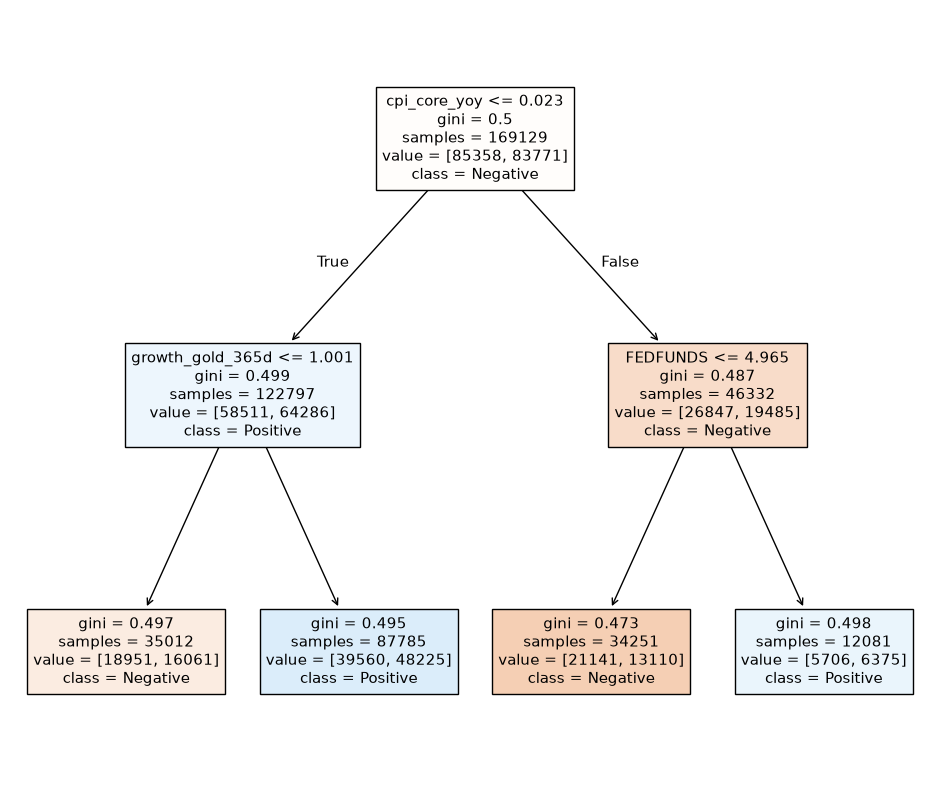

In [103]:
# Visualisation: decision tree for a few levels (max_depth variable)
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Assuming clf_2 is your trained DecisionTreeClassifier
plt.figure(figsize=(12,10))  # Set the size of the figure
plot_tree(clf_2,
          filled=True,
          feature_names=train_columns,
          class_names=['Negative', 'Positive'],
          max_depth=2)
plt.show()

In [104]:
tree_rules = export_text(clf_2, feature_names=list(X_train), max_depth=1)
print(tree_rules)

|--- cpi_core_yoy <= 0.02
|   |--- growth_gold_365d <= 1.00
|   |   |--- class: 0
|   |--- growth_gold_365d >  1.00
|   |   |--- class: 1
|--- cpi_core_yoy >  0.02
|   |--- FEDFUNDS <= 4.96
|   |   |--- class: 0
|   |--- FEDFUNDS >  4.96
|   |   |--- class: 1



## 1.3) [Code Snippet 3] Random Forest
https://scikit-learn.org/stable/modules/ensemble.html#random-forests-and-other-randomized-tree-ensembles

> **Reading note: 1.3 Random forest**
>
> A random forest trains many trees on random parts of the data and lets them vote. That's usually more stable than one tree.
>
> - The search over `max_depth` × `n_estimators` (number of trees) takes ~15 minutes, so its results are pasted in and plotted. As in 1.2.3, the scores are on Test.
> - The chosen model `rf_best` (100 trees, depth 13) is trained once here (~2 min) and used again in Section 2.

In [105]:
from sklearn.ensemble import RandomForestClassifier
import time

In [106]:
%%time
# (15 min runtime FOR v28 or v5e-1 machine) UNCOMMENT BELOW TO RUN HYPERPARAMs optimisation again
# hyper params tuning

precision_matrix = {}
best_precision = 0
best_depth = 0
best_estimators = 1

for depth in [4, 5, 7, 9, 11, 13, 15]:
  for estimators in [10,20,50,100]:
    print(f'Working with HyperParams: depth = {depth}, estimators = {estimators}')

    # Start timing
    start_time = time.time()
    # fitting the tree on X_train, y_train
    rf = RandomForestClassifier(n_estimators = estimators,
                                max_depth = depth,
                                random_state = 42,
                                n_jobs = -1)

    rf = rf.fit(X_train_valid, y_train_valid)

    # getting the predictions for TEST and accuracy score
    y_pred_valid = rf.predict(X_valid)
    precision_valid = precision_score(y_valid, y_pred_valid)
    y_pred_test = rf.predict(X_test)
    precision_test = precision_score(y_test, y_pred_test)
    print(f'  Precision on test is {precision_test}, (precision on valid is {precision_valid} - tend to overfit)')

    # saving to the dict
    precision_matrix[depth, estimators] = round(precision_test,4)

    # Measure elapsed time
    elapsed_time = time.time() - start_time
    print(f'Time for training: {elapsed_time:.2f} seconds, or {elapsed_time/60:.2f} minutes')

    # updating the best precision
    if precision_test >= best_precision:
      best_precision = round(precision_test,4)
      best_depth = depth
      best_estimators = estimators
      print(f'New best precision found for depth={depth}, estimators = {estimators}')

    print('------------------------------')

print(f'Matrix of precisions: {precision_matrix}')
print(f'The best precision is {best_precision} and the best depth is {best_depth} ')

Working with HyperParams: depth = 4, estimators = 10
  Precision on test is 0.5976143141153082, (precision on valid is 0.66015503875969 - tend to overfit)
Time for training: 0.66 seconds, or 0.01 minutes
New best precision found for depth=4, estimators = 10
------------------------------
Working with HyperParams: depth = 4, estimators = 20
  Precision on test is 0.5413450937155457, (precision on valid is 0.6523569656416811 - tend to overfit)
Time for training: 0.70 seconds, or 0.01 minutes
------------------------------
Working with HyperParams: depth = 4, estimators = 50
  Precision on test is 0.5483870967741935, (precision on valid is 0.6639007092198581 - tend to overfit)
Time for training: 1.10 seconds, or 0.02 minutes
------------------------------
Working with HyperParams: depth = 4, estimators = 100
  Precision on test is 0.5210526315789473, (precision on valid is 0.6732428174930613 - tend to overfit)
Time for training: 1.93 seconds, or 0.03 minutes
------------------------------

In [107]:
# uncomment when you run the hyperparam tuning again
# print(precision_matrix)

In [108]:
# pre-calculated best precision matrix (max_depth, n_estimators) for Random Forest
best_precision_matrix_random_forest = {(4, 10): 0.5718, (4, 20): 0.5711, (4, 50): 0.5701, (4, 100): 0.57, (5, 10): 0.5571, (5, 20): 0.5495, (5, 50): 0.5531, (5, 100): 0.5553, (7, 10): 0.5668, (7, 20): 0.592, (7, 50): 0.5804, (7, 100): 0.5737, (9, 10): 0.578, (9, 20): 0.5706, (9, 50): 0.5644, (9, 100): 0.568, (11, 10): 0.5676, (11, 20): 0.5872, (11, 50): 0.5868, (11, 100): 0.5879, (13, 10): 0.5642, (13, 20): 0.5781, (13, 50): 0.5988, (13, 100): 0.6031, (15, 10): 0.5634, (15, 20): 0.5903, (15, 50): 0.5839, (15, 100): 0.6012}



In [109]:

# Convert data to DataFrame
df = pd.DataFrame.from_dict(best_precision_matrix_random_forest, orient='index', columns=['precision_score']).reset_index()

# Rename the columns for clarity
df.columns = ['max_depth_and_metric', 'precision_score']

# Separate the tuple into two columns
df[['max_depth', 'n_estimators']] = pd.DataFrame(df['max_depth_and_metric'].tolist(), index=df.index)

# Drop the combined column
df = df.drop(columns=['max_depth_and_metric'])

# Create line plot using Plotly Express
fig = px.line(df, x='max_depth', y='precision_score', color='n_estimators',
              labels={'max_depth': 'Max Depth', 'precision_score': 'Precision Score', 'n_estimators': 'Number of Estimators'},
              title='Random Forest Models: Precision Score vs. Max Depth for Different Number of Estimators')

# Adjust x-axis range
fig.update_xaxes(range=[4, 15])

# Show the figure
fig.show()

In [110]:
# MANUALLY SELECTED BEST - should have enough complexity and smoothness (n_estimators)
rf_best_n_estimators = 100
# MANUALLY SELECTED BEST - should have enough complexity
rf_best_max_depth = 13

In [111]:
%%time

# several minutes to compute (2 min)

rf_best = RandomForestClassifier(n_estimators = rf_best_n_estimators,
                                 max_depth = rf_best_max_depth,
                                 random_state = 42,
                                 n_jobs = -1)

rf_best = rf_best.fit(X_train_valid, y_train_valid)

CPU times: user 1min 55s, sys: 342 ms, total: 1min 56s
Wall time: 7.72 s


## 1.4) [Code Snippet 1] Logistic Regression
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

There can be many cases when Logistic Regression does not converge: https://forecastegy.com/posts/how-to-solve-logistic-regression-not-converging-in-scikit-learn/

> **Reading note: 1.4 Logistic regression**
>
> A linear model: it adds up the inputs with weights and turns the sum into a probability. It needs inputs on a similar scale, so `StandardScaler` rescales them first. Its precision (~55%) is below the trees, and it isn't used later.
>
> ⚠️ The scaler cell **overwrites** `X_train_valid`, `X_valid` and `X_test` with scaled NumPy arrays. Section 2 then calls `clf_best.predict_proba(X_test)`, but `clf_best` was trained on unscaled data. If you run this cell, re-run the data cells from 1.2.3 before Section 2, or save the scaled data under new names.

In [112]:
from sklearn.linear_model import LogisticRegression

In [113]:
# Large feature magnitudes can cause convergence issues. If you haven’t already, scale your data:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_valid = scaler.fit_transform(X_train_valid)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [114]:
# UNCOMMENT TO RUN IT AGAIN - at least 10 min to run

# precision_matrix = {}
# best_precision = 0
# best_C = 0
# best_iter = 0

# for c in [1, 0.1, 0.01]:
#   for iter in [50, 100, 200]:
#     print(f'Working with HyperParams: C = {c} (positive float, smaller = stronger regularization), max_iter={iter}')
#     # fitting the tree on X_train, y_train
#     # hyperParam C should be between 0 and 1
#     lr = LogisticRegression(C=c,
#                             random_state=42,
#                             max_iter=iter,
#                             solver='sag',  # 'sag' - another option
#                             n_jobs=-1)

#     lr = lr.fit(X_train_valid, y_train_valid)

#     # getting the predictions for TEST and accuracy score
#     y_pred_valid = lr.predict(X_valid)
#     precision_valid = precision_score(y_valid, y_pred_valid)
#     y_pred_test = lr.predict(X_test)
#     precision_test = precision_score(y_test, y_pred_test)
#     print(f'  Precision on test is {precision_test}, (precision on valid is {precision_valid} - tend to overfit)')
#     # saving to the dict
#     precision_matrix[(c,iter)] = round(precision_test,4)
#     # updating the best precision
#     if precision_test >= best_precision:
#       best_precision = round(precision_test,4)
#       best_C = c
#       best_iter = iter
#       print(f'New best precision found for C={c}')
#       print('------------------------------')

# print(f'Matrix of precisions: {precision_matrix}')
# print(f'The best precision is {best_precision} and the best C is {best_C}, best max_iter = {best_iter}  ')

In [115]:
# UNCOMMENT TO SEE THE RESULTS OF THE RUN
# print(precision_matrix)

In [116]:
# Logistic regression: Precomputed precision matrix from the above
best_precision_matrix_logistic_regression = {(1, 50): 0.5553, (1, 100): 0.5559, (1, 200): 0.5444, (0.1, 50): 0.5548, (0.1, 100): 0.5548, (0.1, 200): 0.5478, (0.01, 50): 0.5496, (0.01, 100): 0.5516, (0.01, 200): 0.5509}

In [117]:
list(best_precision_matrix_logistic_regression.items())[0]

((1, 50), 0.5553)

In [118]:
# Prepare the data
rows = []
for key, value in list(best_precision_matrix_logistic_regression.items()):
    C, max_iter = key
    combination_label = f'C={C}, max_iter={max_iter}'
    rows.append({'Combination': combination_label, 'Precision': value})

df = pd.DataFrame(rows)
df.loc[:,'Precision'] = df.Precision*100.0 # need for % visualisation

# Create the bar chart
fig = px.bar(df,
             x='Combination',
             y='Precision',
             text='Precision'
             )

# Customize the layout for better readability
fig.update_layout(
    xaxis_title='Hyperparams combinations of <C, Max Iterations>',
    yaxis_title='Precision Score',
    xaxis_tickangle=-45,
    title={
        'text': 'Precision Scores for Various Logistic Regression Hyperparameter Combinations',
        'y':0.95,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    }
)


# Update the text position
fig.update_traces(texttemplate='%{text:.2f}%',
                  textposition='inside',
                  textfont_color='white')

# Show the figure
fig.show()

## 1.5) [Code Snippet 4 - ADVANCED] Neural Network (NN) and HyperParams tuning
* [Tutorial from Tensorflow.org](https://www.tensorflow.org/tutorials/keras/classification)
* [TowardsDataScience Hyperparameter Optimization with Keras](https://towardsdatascience.com/hyperparameter-optimization-with-keras-b82e6364ca53)
* [Machine Learning Mastery tutorial with Keras Deep Learning](https://machinelearningmastery.com/binary-classification-tutorial-with-the-keras-deep-learning-library/)

> **Reading note: 1.5 Neural network (optional / advanced)**
>
> A small Keras network: two hidden layers with dropout, and a sigmoid output that gives a probability of "up". `train_neural_network_with_hyperparams` tries combinations from the parameter grid and keeps the model with the best validation accuracy.
>
> The training is commented out, and a saved `best_history_nn` is plotted instead. In the plot, training precision rises while test precision stays flat, so the network memorises the past without getting better at the future. You can skip this section without breaking anything later. It needs TensorFlow, so Python 3.13 or older.

In [119]:
# https://towardsdatascience.com/hyperparameter-optimization-with-keras-b82e6364ca53


# Extended params set

# p = {'lr': [0.01, 0.03,0.1, 0.3,1,3,10],
#      'first_neuron': [0,16,32,64,128,256],
#      'second_neuron':[0,16,32,64,128,256],
#      'first_dropout':[0,0.2,0.3],
#      'second_dropout':[0,0.2,0.3],
#      'activation_first':['relu','sigmoid','linear'],
#      'activation_second':['relu','sigmoid','linear'],
#     #  'activation_first':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
#     #  'activation_second':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
#     #  'batch_size':(2,30,10),
#     #  'loss': ('mse','mae'),
#     #  'epochs':[150],
#     #  'shape': ['brick','long_funnel'],
#      'optimizer':['adam', 'nadam', 'rmaprop','sgd'],
#     #  'losses': [logcosh, binary_crossentropy],
#     #  'last_activation':[sigmoid]
#      }


# Reduced params set and available options
p = {'lr': [0.1],
     'first_neuron': [12,24,32,48,96, 128, 196, 256],
     'second_neuron':[12,24,32,48,96, 128, 196, 256],
     'first_dropout':[0.1],
     'second_dropout':[0.1],
     'activation_first':['relu','sigmoid','softplus','tanh'],
     'activation_second':['relu'],
    #  'activation_first':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
    #  'activation_second':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
    #  'batch_size':(2,30,10),
    #  'loss': ('mse','mae'),
    #  'epochs':[150],
    #  'shape': ['brick','long_funnel'],
     'optimizer':['adam','nadam','sgd','rmaprop'],
    #  'losses': [logcosh, binary_crossentropy],
    #  'last_activation':[sigmoid]
     }


# Number of models to run and write to SHEETS:
count_models=0

nn_params = {}

for lr in p['lr']:
  for first_neuron in p['first_neuron']:
    for second_neuron in p['second_neuron']:
      for first_dropout in p['first_dropout']:
        for second_dropout in p['second_dropout']:
          for activation_first in p['activation_first']:
            for activation_second in p['activation_second']:
              for optimizer in p['optimizer']:
                # print(lr,first_neuron,second_neuron,first_dropout,second_dropout,activation_first,activation_second,optimizer,sep='/')
                count_models=count_models+1
                nn_params['learning_rate'] = lr
                nn_params['first_layer_neurons'] = first_neuron
                nn_params['first_layer_dropout'] = first_dropout
                nn_params['second_layer_neurons'] = second_neuron
                nn_params['second_layer_dropout'] = second_dropout
                nn_params['activation_first_layer'] = activation_first
                nn_params['activation_second_layer'] = activation_second
                nn_params['optimizer'] = optimizer
                # features count as an input shape
                nn_params['input_shape'] = len(X_train.keys())

# Current set of models to try
print(count_models)

1024


In [120]:
nn_params

{'learning_rate': 0.1,
 'first_layer_neurons': 256,
 'first_layer_dropout': 0.1,
 'second_layer_neurons': 256,
 'second_layer_dropout': 0.1,
 'activation_first_layer': 'tanh',
 'activation_second_layer': 'relu',
 'optimizer': 'rmaprop',
 'input_shape': 301}

In [121]:
# you need to install TF if using a v28 machine
# !pip install tensorflow

In [122]:
import tensorflow as tf
import keras
from keras import layers
# from keras.models import Sequential
# from keras.layers import Dense, Input, Dropout, Activation

I0000 00:00:1793361759.154057  107822 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793361759.183174  107822 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793361759.848724  107822 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [123]:
# building one Neural Network when Parameters are known:
import datetime

# len(rez_train.keys())
def build_model(nn_params):
  # lr, first_neuron, second_neuron, first_dropout, second_dropout, activation_first, activation_second, optimizer
  model = keras.Sequential([
  layers.Dense(nn_params['first_layer_neurons'],
               activation=nn_params['activation_first_layer'],
               input_shape=[nn_params['input_shape']]),
  layers.Dropout(nn_params['first_layer_dropout']),
  layers.Dense(nn_params['second_layer_neurons'],
               activation=nn_params['activation_second_layer']),
  layers.Dropout(nn_params['second_layer_dropout']),
  layers.Dense(1, activation='sigmoid') # sigmoid is important for a Neural Network
  ])

  if optimizer == 'adam':
    opt = keras.optimizers.Adam(lr)
  elif optimizer == 'nadam':
    opt = keras.optimizers.Nadam(lr)
  elif optimizer == 'rmsprop':
    opt = keras.optimizers.RMSprop(lr)
  elif optimizer == 'sgd':
    opt = keras.optimizers.SGD(lr)
  else:
    opt = keras.optimizers.Adagrad(lr)
  model.compile(loss='binary_crossentropy', # mae/rmse for the Regression,
                optimizer=opt,
                metrics=['accuracy',keras.metrics.Precision()]) # or use [keras.metrics.Precision()] for a binary model : https://keras.io/api/metrics/classification_metrics/#precision-class
  return model

In [124]:
nn_params

{'learning_rate': 0.1,
 'first_layer_neurons': 256,
 'first_layer_dropout': 0.1,
 'second_layer_neurons': 256,
 'second_layer_dropout': 0.1,
 'activation_first_layer': 'tanh',
 'activation_second_layer': 'relu',
 'optimizer': 'rmaprop',
 'input_shape': 301}

In [125]:

model = build_model(nn_params)
model.summary()
# model.get_config()

/home/alexis/projects/stock-market-analytics-zoomcamp/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1793361760.058266  107822 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793361760.058502  111095 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793361760.079401  107822 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        77,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 143,361 (560.00 KB)

 Trainable params: 143,361 (560.00 KB)

 Non-trainable params: 0 (0.00 B)

In [126]:
# trainable params in the model with max params (largest hidden layers size)
model.count_params()

143361

In [127]:
# Display training progress by printing a single dot for each completed epoch
class PrintDot(keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs):
    if epoch % 100 == 0: print()
    print('.', end='')

In [128]:
# read tutorial about Binary Classification with Neural Network
# https://machinelearningmastery.com/binary-classification-tutorial-with-the-keras-deep-learning-library/
# https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit


# HYPER_PARAMS_SPACE = PARAMS space
# WHEN MAX_MODELS>0: return after MAX_MODELS checked
# MAX_EPOCHS: how many epochs (periods when model weights are updated) do we need?
def train_neural_network_with_hyperparams(HYPER_PARAMS_SPACE, MAX_MODELS=0, MAX_EPOCHS=250, EARLY_STOPPING_PATIENCE=20):

  # The patience parameter is the amount of epochs to check for improvement
  early_stop = keras.callbacks.EarlyStopping(monitor='val_accuracy',  # we want accuracy to improve every single iteration (or at least in several iterations (EARLY STOPPING PARAM))
                                             patience = EARLY_STOPPING_PATIENCE)
  nn_params = {} # current hyperParams settings
  cur = 0 # models trained

  # best stats
  best_accuracy = 0
  best_model = None
  best_history = None

  for lr in HYPER_PARAMS_SPACE['lr']:
    for first_dropout in HYPER_PARAMS_SPACE['first_dropout']:
      for second_dropout in HYPER_PARAMS_SPACE['second_dropout']:
        for activation_first in HYPER_PARAMS_SPACE['activation_first']:
          for activation_second in HYPER_PARAMS_SPACE['activation_second']:
            for optimizer in HYPER_PARAMS_SPACE['optimizer']:
              for first_neuron in HYPER_PARAMS_SPACE['first_neuron']:
                for second_neuron in HYPER_PARAMS_SPACE['second_neuron']:
                  cur = cur+1

                  nn_params['learning_rate'] = lr
                  nn_params['first_layer_neurons'] = first_neuron
                  nn_params['first_layer_dropout'] = first_dropout
                  nn_params['second_layer_neurons'] = second_neuron
                  nn_params['second_layer_dropout'] = second_dropout
                  nn_params['activation_first_layer'] = activation_first
                  nn_params['activation_second_layer'] = activation_second
                  nn_params['optimizer'] = optimizer

                  # features count as an input shape
                  nn_params['input_shape'] = len(X_train.keys())

                  print(f'Using HyperParams:{nn_params}')

                  model = build_model(nn_params)
                  # model.summary()

                  frame = pd.DataFrame(data=[cur,lr,first_neuron,second_neuron,first_dropout,second_dropout, activation_first, activation_second, optimizer])

                  print(f"Training model {cur} with trainable params {model.count_params()} :")
                  t_start = datetime.datetime.now()
                  history = model.fit(
                                        X_train_valid,
                                        y_train_valid,
                                        epochs=MAX_EPOCHS,
                                        validation_data = (X_test, y_test),
                                        verbose=1, #change to 0 if you don't want to see the progress
                                        callbacks=[early_stop,PrintDot()])

                  t_diff = datetime.datetime.now() - t_start
                  frame = pd.DataFrame(data=[t_diff.seconds,
                                          len(history.epoch),
                                          history.history['val_accuracy'][0], # start of learning
                                          history.history['val_accuracy'][len(history.epoch)-1], # end of learning
                                          #  history.history['val_precision_2'][0], # start of learning
                                          #  history.history['val_precision_2'][len(history.epoch)-1], # end of learning
                                          ])

                  if history.history['val_accuracy'][len(history.epoch)-1]> best_accuracy:
                    best_accuracy = history.history['val_accuracy'][len(history.epoch)-1]
                    best_model = model
                    best_history = history

                  # early stopping of hyper params loop
                  if MAX_MODELS>0 and cur>=MAX_MODELS:
                    return best_model, best_history.history

                  print('==============================================================')

  return best_model, best_history.history #full hyper params search on all models

In [129]:
# UNCOMMENT TO RUN IT
# returns best_model (trained) and best_history (history of train operations)
# best_model, best_history = train_neural_network_with_hyperparams(HYPER_PARAMS_SPACE=p,
#                                                                  MAX_MODELS=2, #not more than 2 models
#                                                                  MAX_EPOCHS=250,
#                                                                  EARLY_STOPPING_PATIENCE=10
#                                                                  )

In [130]:
# UNCOMMENT WHEN RUN AGAIN

# best_history_nn = best_history
# best_model_nn = best_model

In [131]:
# best_model_nn.summary()

In [132]:
# check the best history of training
# best_history

In [133]:
# pre computed history
best_history_nn ={'accuracy': [0.6206425428390503,
  0.6563935875892639,
  0.6715070605278015,
  0.6781659126281738,
  0.6846689581871033,
  0.6899000406265259,
  0.6924314498901367,
  0.6940774321556091,
  0.6963594555854797,
  0.6981488466262817,
  0.6982797980308533,
  0.7005742192268372],
 'loss': [0.6485477089881897,
  0.6164013743400574,
  0.6015466451644897,
  0.5939826965332031,
  0.5864177346229553,
  0.5822728872299194,
  0.5788451433181763,
  0.5766140818595886,
  0.5728825926780701,
  0.5714946389198303,
  0.5709761381149292,
  0.5681091547012329],
 'precision_1': [0.6281318068504333,
  0.6705082058906555,
  0.6927300691604614,
  0.7030346393585205,
  0.7096523642539978,
  0.7157368659973145,
  0.7195449471473694,
  0.7237764596939087,
  0.724949061870575,
  0.7277039289474487,
  0.7285037040710449,
  0.7305046916007996],
 'val_accuracy': [0.5095517039299011,
  0.5176388025283813,
  0.5059220790863037,
  0.49360036849975586,
  0.4926133453845978,
  0.4922631084918976,
  0.49605196714401245,
  0.48605450987815857,
  0.48605450987815857,
  0.4821383059024811,
  0.47784003615379333,
  0.4782857894897461],
 'val_loss': [0.7736297845840454,
  0.9822676181793213,
  1.0234887599945068,
  1.1025390625,
  1.1842303276062012,
  1.1674247980117798,
  1.1660196781158447,
  1.2397290468215942,
  1.2409558296203613,
  1.2863727807998657,
  1.3408353328704834,
  1.328245759010315],
 'val_precision_1': [0.5571497082710266,
  0.5591427087783813,
  0.5572323799133301,
  0.5471343398094177,
  0.5460649728775024,
  0.546144962310791,
  0.5497111082077026,
  0.5439006090164185,
  0.5426294207572937,
  0.5389731526374817,
  0.5362157225608826,
  0.5376880168914795]}

In [134]:
X_train_valid.shape

(169129, 301)

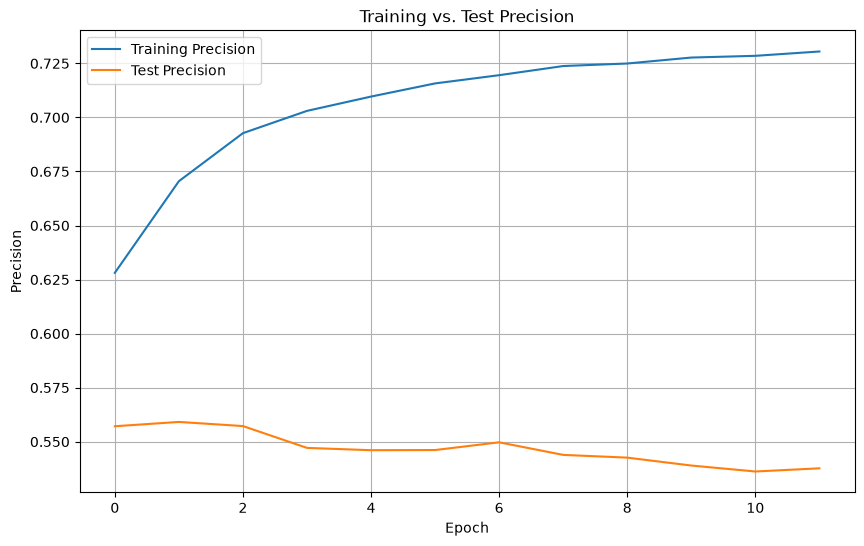

In [135]:
# Learning visualisation for the Deep Neural Network (DNN)
# The model is not actually training, as the precision and accuracy score are not improving on TRAIN/TEST with more Epochs

# Plotting accuracy
plt.figure(figsize=(10, 6))
plt.plot(best_history_nn['precision_1'], label='Training Precision')
plt.plot(best_history_nn['val_precision_1'], label='Test Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.title('Training vs. Test Precision')
plt.legend()
plt.grid(True)
plt.show()

# 2) [Code Snippet 5] Different Decision rules to improve the Precision (varying Threshold)
* best model1 **(clf_best)**: Decision Tree (max_depth=7 - second best)
* best model2 **(rf_best)**: Random Forest (n_estimators=100, max_depth=13)

## 2.1. Predicting probabilities (predict_proba), getting the distribution for probabilities, and new decision rules

In [136]:
# predicting probability instead of a label
# y_pred_test = clf_best.predict_proba(X_test)                                         ## Q2: commented out

# Q2: X_test was overwritten by StandardScaler in 1.4 (Logistic Regression),           ## ADDED
# so rebuild the unscaled test features the Random Forest was trained on               ## ADDED
X_test_rf = clean_dataframe_from_inf_and_nan(test_df[features_list].copy())            ## ADDED
y_pred_test = rf_best.predict_proba(X_test_rf)                                         ## Q2: uncommented

y_pred_test_class1 = [k[1] for k in y_pred_test] # k[1] is the second element in the list of Class predictions

In [137]:
# example prediction
y_pred_test

array([[0.70759301, 0.29240699],
       [0.66943162, 0.33056838],
       [0.66869888, 0.33130112],
       ...,
       [0.51001762, 0.48998238],
       [0.52791068, 0.47208932],
       [0.56254529, 0.43745471]], shape=(33163, 2))

In [138]:
y_pred_test_class1_df = pd.DataFrame(y_pred_test_class1, columns=['Class1_probability'])

# sample of predictions
y_pred_test_class1_df.sample(10)

,Class1_probability
27744,0.473467
12003,0.426470
5408,0.337831
17089,0.436751
8548,0.274862
14055,0.446017
19642,0.374132
18216,0.389436
21511,0.445428
29068,0.412329


In [139]:
# Mean prediction is 0.61, median is 0.56, 75% quantile is 0.67
y_pred_test_class1_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Class1_probability,33163.0,0.406866,0.055261,0.2293,0.367383,0.404807,0.44504,0.67827


In [140]:
# Unconditional probability of a positive growth is 57%
y_test.sum()/y_test.count()

np.float64(0.47028314688055967)

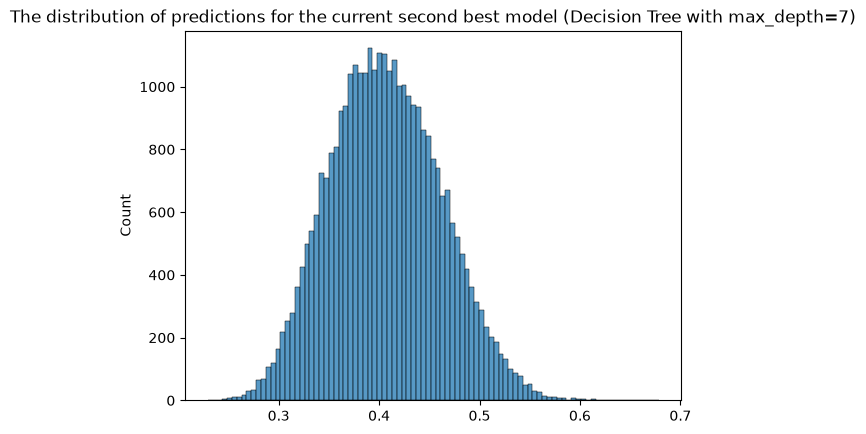

In [141]:
sns.histplot(y_pred_test_class1)

# Add a title
plt.title(f'The distribution of predictions for the current second best model (Decision Tree with max_depth={clf_best.get_depth()})')

# Show the plot
plt.show()

In [142]:
# tpr (True Positive Rate) vs. fpr (False Positive Rate) dataframe
# tp = True Positive
# tn = True Negative
# fp = False Positive
# fn = False Negative
# Decision Rule :  "y_pred>= Threshold" for Class "1"

# when only_even=True --> we'll have a step ==0.02 and leave only even records

def tpr_fpr_dataframe(y_true, y_pred, only_even=False):
    scores = []

    if only_even==False:
      thresholds = np.linspace(0, 1, 101) #[0, 0.01, 0.02, ...0.99,1.0]
    else:
      thresholds = np.linspace(0, 1, 51) #[0, 0.02, 0.04,  ...0.98,1.0]

    for t in thresholds:

        actual_positive = (y_true == 1)
        actual_negative = (y_true == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        if tp + fp > 0:
          precision = tp / (tp + fp)

        if tp + fn > 0:
          recall = tp / (tp + fn)

        if precision+recall > 0:
          f1_score = 2*precision*recall / (precision+recall)

        accuracy = (tp+tn) / (tp+tn+fp+fn)

        scores.append((t, tp, fp, fn, tn, precision, recall, accuracy, f1_score))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn','precision','recall', 'accuracy','f1_score']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores


In [143]:
df_scores = tpr_fpr_dataframe(y_test,
                              y_pred_test_class1,
                              only_even=True)

In [144]:
# full df_scores
df_scores

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
0,0.00,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
1,0.02,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
2,0.04,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
3,0.06,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
4,0.08,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
5,0.10,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
6,0.12,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
7,0.14,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
8,0.16,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000
9,0.18,15596,17567,0,0,0.470283,1.000000,0.470283,0.639718,1.000000,1.000000


In [145]:
df_scores[(df_scores.threshold>=0.5) & (df_scores.threshold<=0.82)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
25,0.50,933,745,14663,16822,0.556019,0.059823,0.535386,0.108024,0.059823,0.042409
26,0.52,457,297,15139,17270,0.606101,0.029302,0.534542,0.055902,0.029302,0.016907
27,0.54,182,106,15414,17461,0.631944,0.011670,0.532009,0.022916,0.011670,0.006034
28,0.56,62,31,15534,17536,0.666667,0.003975,0.530652,0.007904,0.003975,0.001765
29,0.58,33,10,15563,17557,0.767442,0.002116,0.530410,0.004220,0.002116,0.000569
30,0.60,15,4,15581,17563,0.789474,0.000962,0.530049,0.001921,0.000962,0.000228
31,0.62,7,0,15589,17567,1.000000,0.000449,0.529928,0.000897,0.000449,0.000000
32,0.64,5,0,15591,17567,1.000000,0.000321,0.529868,0.000641,0.000321,0.000000
33,0.66,2,0,15594,17567,1.000000,0.000128,0.529777,0.000256,0.000128,0.000000
34,0.68,0,0,15596,17567,1.000000,0.000000,0.529717,0.000000,0.000000,0.000000


In [146]:
# TODO: HA to build a similar dataframe for random_forest and find optimal thresholds

<Axes: title={'center': 'Precision vs. Recall for the Best Model (Decision Tree with max_depth=15)'}, xlabel='threshold'>

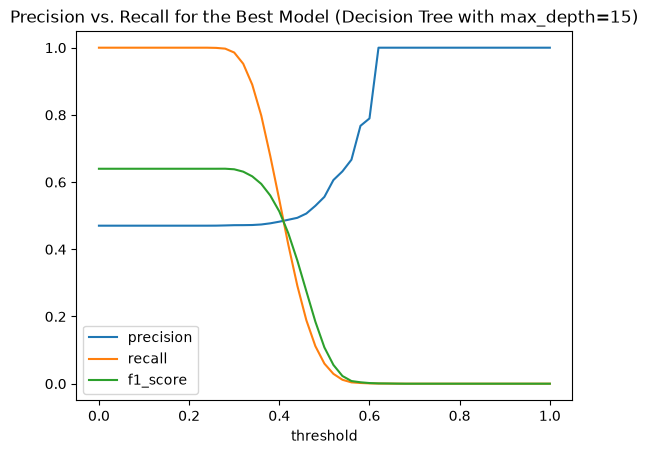

In [147]:
# Try to find high Precision score points

df_scores.plot.line(x='threshold',
                    y=['precision','recall', 'f1_score'],
                    title = 'Precision vs. Recall for the Best Model (Decision Tree with max_depth=15)')

## 2.2) [Code Snippet 6] Defining new columns with Predictions in new_df: pred7..pred10
* pred7 and pred8 are 2 decision rules for the Decision Tree (best model with max_depth=15)
* pred9 and pred10 are 2 decision rules for the Random Forest (second best model)

> **Reading note: 2.2 New prediction columns from thresholds**
>
> Four new predictions are added (the heading's numbers are outdated):
> - `pred8_clf_second_best_rule_56`, `pred9_clf_second_best_rule_66`: the depth-7 tree with thresholds 0.56 and 0.66
> - `pred10_rf_best_rule_55`, `pred11_rf_best_rule_65`: the random forest with thresholds 0.55 and 0.65
>
> The `proba_predN` columns keep the raw probabilities. The histograms show **when** each rule says "up" and **how many stocks per day** it picks (out of 33). That number matters in Section 3, because it decides how much money you need. Note that `pred10_daily_positive_count` actually counts `pred11`, and `pred9_daily_positive_count` counts `pred10`.

In [148]:
# existing predictions
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds',
 'pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best']

In [149]:
# adding Decision Tree predictors (clf_best) to the dataset for 2 new rules: Threshold = 0.66 and 0.78


y_pred_all = clf_best.predict_proba(X_all)
y_pred_all_class1 = [k[1] for k in y_pred_all] #list of predictions for class "1"
y_pred_all_class1_array = np.array(y_pred_all_class1) # (Numpy Array) np.array of predictions for class "1" , converted from a list

# defining a new prediction vector is easy now, as the dimensions will match
new_df['proba_pred8'] = y_pred_all_class1_array
new_df['pred8_clf_second_best_rule_56'] = (y_pred_all_class1_array >= 0.56).astype(int)

new_df['proba_pred9'] = y_pred_all_class1_array
new_df['pred9_clf_second_best_rule_66'] = (y_pred_all_class1_array >= 0.66).astype(int)


In [150]:
# adding Random Forest predictors (rf_best)
rf_best

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",13
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [151]:
# make predictions of probabilities using the Random Forest model (rf_best)

y_pred_all = rf_best.predict_proba(X_all)
y_pred_all_class1 = [k[1] for k in y_pred_all] #list of predictions for class "1"
y_pred_all_class1_array = np.array(y_pred_all_class1) # (Numpy Array) np.array of predictions for class "1" , converted from a list


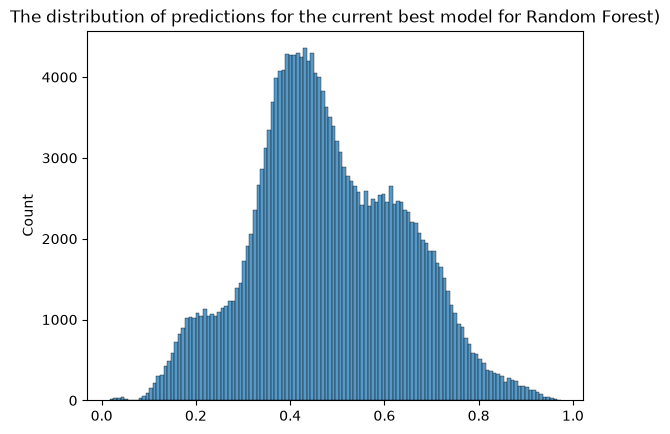

In [152]:
# PREDICTIONS ON A FULL DATASET - more smooth dataset - good sign
sns.histplot(y_pred_all_class1)

# Add a title
plt.title('The distribution of predictions for the current best model for Random Forest)')

# Show the plot
plt.show()

In [153]:
# adding Random Forest predictors (rf_best) to the dataset for 2 new rules: Threshold = 0.60 and 0.70
# defining a new prediction vector is easy now, as the dimensions will match
new_df['proba_pred10'] = y_pred_all_class1_array
new_df['pred10_rf_best_rule_55'] = (y_pred_all_class1_array >= 0.55).astype(int)

new_df['proba_pred11'] = y_pred_all_class1_array
new_df['pred11_rf_best_rule_65'] = (y_pred_all_class1_array >= 0.65).astype(int)

# Q2: more Random Forest decision rules, thresholds 0.56 ... 0.64                       ## ADDED
new_df['pred12_rf_best_rule_56'] = (y_pred_all_class1_array >= 0.56).astype(int)   ## ADDED
new_df['pred13_rf_best_rule_57'] = (y_pred_all_class1_array >= 0.57).astype(int)   ## ADDED
new_df['pred14_rf_best_rule_58'] = (y_pred_all_class1_array >= 0.58).astype(int)   ## ADDED
new_df['pred15_rf_best_rule_59'] = (y_pred_all_class1_array >= 0.59).astype(int)   ## ADDED
new_df['pred16_rf_best_rule_60'] = (y_pred_all_class1_array >= 0.60).astype(int)   ## ADDED
new_df['pred17_rf_best_rule_61'] = (y_pred_all_class1_array >= 0.61).astype(int)   ## ADDED
new_df['pred18_rf_best_rule_62'] = (y_pred_all_class1_array >= 0.62).astype(int)   ## ADDED
new_df['pred19_rf_best_rule_63'] = (y_pred_all_class1_array >= 0.63).astype(int)   ## ADDED
new_df['pred20_rf_best_rule_64'] = (y_pred_all_class1_array >= 0.64).astype(int)   ## ADDED

<Axes: >

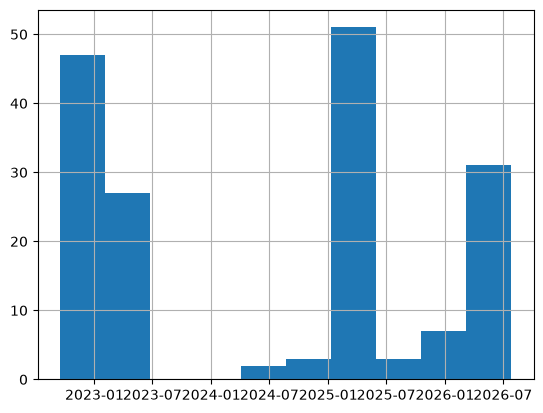

In [154]:
# Many positive predictions
new_df[(new_df.split=='test')&(new_df.pred10_rf_best_rule_55==1)].Date.hist()

<Axes: >

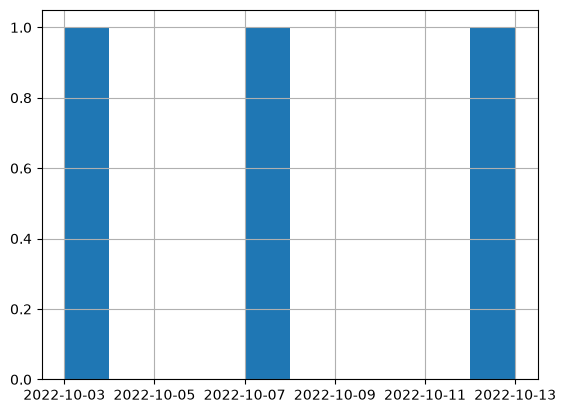

In [155]:
# When did it predict to trade for the "rare" positive prediction pred10?
new_df[(new_df.split=='test')&(new_df.pred11_rf_best_rule_65==1)].Date.hist()

In [156]:
## sample of rare predictions with high threshold
# new_df[(new_df.split=='test')&(new_df.pred11_rf_best_rule_65==1)].sort_values(by='Date').sample(10)

# sample of rare predictions with high threshold
rare = new_df[(new_df.split=='test') & (new_df.pred11_rf_best_rule_65==1)]
print(f'{len(rare)} rare predictions on TEST')
rare.sample(min(10, len(rare))).sort_values(by='Date')


3 rare predictions on TEST


,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,pred11_rf_best_rule_65,pred12_rf_best_rule_56,pred13_rf_best_rule_57,pred14_rf_best_rule_58,pred15_rf_best_rule_59,pred16_rf_best_rule_60,pred17_rf_best_rule_61,pred18_rf_best_rule_62,pred19_rf_best_rule_63,pred20_rf_best_rule_64
3198,4.559789,4.634902,4.537697,4.626065,3658000.0,0.0,0.0,IDEXY,2022,October,...,1,1,1,1,1,1,1,1,1,1
3202,4.643739,4.665831,4.568626,4.590718,591600.0,0.0,0.0,IDEXY,2022,October,...,1,1,1,1,1,1,1,1,1,1
3206,4.590718,4.802801,4.564208,4.758617,857800.0,0.0,0.0,IDEXY,2022,October,...,1,1,1,1,1,1,1,1,1,1


In [157]:
# List of ALL current predictions
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds',
 'pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best',
 'pred8_clf_second_best_rule_56',
 'pred9_clf_second_best_rule_66',
 'pred10_rf_best_rule_55',
 'pred11_rf_best_rule_65',
 'pred12_rf_best_rule_56',
 'pred13_rf_best_rule_57',
 'pred14_rf_best_rule_58',
 'pred15_rf_best_rule_59',
 'pred16_rf_best_rule_60',
 'pred17_rf_best_rule_61',
 'pred18_rf_best_rule_62',
 'pred19_rf_best_rule_63',
 'pred20_rf_best_rule_64']

In [158]:
# Pred 10: How many positive prediction per day (out of 33 stocks possible)
pred10_daily_positive_count = pd.DataFrame(new_df[(new_df.split=='test')&(new_df.pred11_rf_best_rule_65==1)].groupby('Date')['pred11_rf_best_rule_65'].count())

In [159]:
# Pred 9: How many positive prediction per day (out of 33 stocks possible)
pred9_daily_positive_count = pd.DataFrame(new_df[(new_df.split=='test')&(new_df.pred10_rf_best_rule_55==1)].groupby('Date')['pred10_rf_best_rule_55'].count())

In [160]:
# Unique trading days on Test (4 years)
new_df[(new_df.split=='test')].Date.nunique()

1040

In [161]:
pred10_daily_positive_count

,pred11_rf_best_rule_65
Date,
2022-10-03,1
2022-10-07,1
2022-10-13,1


array([[<Axes: title={'center': 'pred11_rf_best_rule_65'}>]], dtype=object)

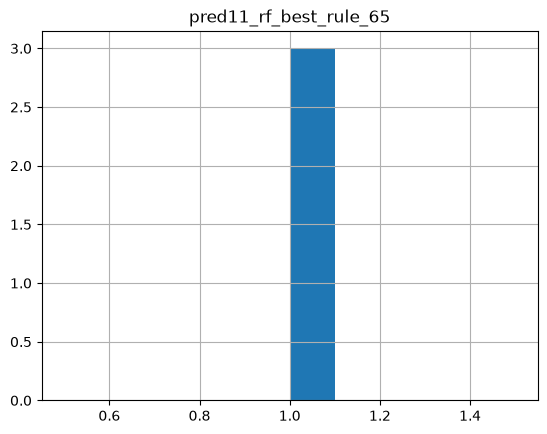

In [162]:
pred10_daily_positive_count.hist()

In [163]:
# 75% cases we have not more than 6 bets of $100
pred10_daily_positive_count.describe().T

,count,mean,std,min,25%,50%,75%,max
pred11_rf_best_rule_65,3.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


array([[<Axes: title={'center': 'pred10_rf_best_rule_55'}>]], dtype=object)

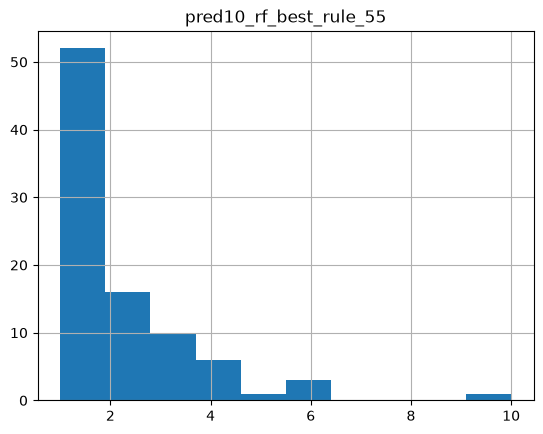

In [164]:
pred9_daily_positive_count.hist()

In [165]:
pred9_daily_positive_count.describe().T

,count,mean,std,min,25%,50%,75%,max
pred10_rf_best_rule_55,89.0,1.921348,1.531671,1.0,1.0,1.0,2.0,10.0


## 2.3) Agg. stats on ALL predictions

> **Reading note: 2.3 All predictions side by side**
>
> Precision is recalculated for every `pred…` column. `PREDICTIONS_ON_MODELS` keeps only model-based ones (`pred5` and up) by reading the number after `pred`. The `count / sum / mean` table shows how often each prediction says "up" per split. A rule that is very precise but almost never fires won't make much money.

In [166]:
# let's review the Predictions:
PREDICTIONS, IS_CORRECT = get_predictions_correctness(new_df, to_predict='is_positive_growth_30d_future')


Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10', 'pred6_clf_4', 'pred7_clf_second_best', 'pred8_clf_second_best_rule_56', 'pred9_clf_second_best_rule_66', 'pred10_rf_best_rule_55', 'pred11_rf_best_rule_65', 'pred12_rf_best_rule_56', 'pred13_rf_best_rule_57', 'pred14_rf_best_rule_58', 'pred15_rf_best_rule_59', 'pred16_rf_best_rule_60', 'pred17_rf_best_rule_61', 'pred18_rf_best_rule_62', 'pred19_rf_best_rule_63', 'pred20_rf_best_rule_64']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4', 'is_correct_pred5', 'is_correct_pred6', 'is_correct_pred7', 'is_correct_pred8', 'is_correct_pred9', 'is_correct_pred10', 'is_correct_pred11', 'is_correct_pred12', 'is_correct_pred13', 'is_correct_pred14', 'is_correct_pred15', 'is_correct_pred16', 'is_correct_pred17', 'is_correct_pred18', 'is_correct_pr

In [167]:
# check approx. periods : Train is 2000-01...2017-01, Valid is 2017-01..2020-09, Test is 2020-09..2024-05
new_df.groupby('split').Date.agg(['min','max'])

,min,max
split,,
test,2022-09-16,2026-09-18
train,2000-01-03,2018-09-13
validation,2018-09-14,2022-09-15


In [168]:
# GET PREDICTION NUMBER: Easier solution not using regular expressions

# Example string
example_string = "pred10_rf_best_rule_60"

# Split the string by '_'
parts = example_string.split('_')

# Extract the part with 'pred' and remove the 'pred' prefix
pred_number = parts[0].replace('pred', '')

# Print the result
print(pred_number)

# Print in one line
print(int(example_string.split('_')[0].replace('pred', '')))


10
10


In [169]:
# all predictions
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds',
 'pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best',
 'pred8_clf_second_best_rule_56',
 'pred9_clf_second_best_rule_66',
 'pred10_rf_best_rule_55',
 'pred11_rf_best_rule_65',
 'pred12_rf_best_rule_56',
 'pred13_rf_best_rule_57',
 'pred14_rf_best_rule_58',
 'pred15_rf_best_rule_59',
 'pred16_rf_best_rule_60',
 'pred17_rf_best_rule_61',
 'pred18_rf_best_rule_62',
 'pred19_rf_best_rule_63',
 'pred20_rf_best_rule_64']

In [170]:
# all predictions on MODELS (not-manual predictions)
PREDICTIONS_ON_MODELS = [p for p in PREDICTIONS if int(p.split('_')[0].replace('pred', ''))>=5]
PREDICTIONS_ON_MODELS

['pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best',
 'pred8_clf_second_best_rule_56',
 'pred9_clf_second_best_rule_66',
 'pred10_rf_best_rule_55',
 'pred11_rf_best_rule_65',
 'pred12_rf_best_rule_56',
 'pred13_rf_best_rule_57',
 'pred14_rf_best_rule_58',
 'pred15_rf_best_rule_59',
 'pred16_rf_best_rule_60',
 'pred17_rf_best_rule_61',
 'pred18_rf_best_rule_62',
 'pred19_rf_best_rule_63',
 'pred20_rf_best_rule_64']

In [171]:
# all predictions on Models - correctness
IS_CORRECT_ON_MODELS = [p for p in IS_CORRECT if int(p.replace('is_correct_pred', ''))>=5]
IS_CORRECT_ON_MODELS

['is_correct_pred5',
 'is_correct_pred6',
 'is_correct_pred7',
 'is_correct_pred8',
 'is_correct_pred9',
 'is_correct_pred10',
 'is_correct_pred11',
 'is_correct_pred12',
 'is_correct_pred13',
 'is_correct_pred14',
 'is_correct_pred15',
 'is_correct_pred16',
 'is_correct_pred17',
 'is_correct_pred18',
 'is_correct_pred19',
 'is_correct_pred20']

In [172]:
# predictions on models
# pred10_rf_best_rule_60: ONLY 2% of TEST cases predicted with high confidence of growth
new_df.groupby('split')[PREDICTIONS_ON_MODELS].agg(['count','sum','mean']).T

split                                        test          train    validation
pred5_clf_10                  count  33163.000000  136842.000000  32287.000000
                              sum     7337.000000   71399.000000  21239.000000
                              mean       0.221241       0.521762      0.657819
pred6_clf_4                   count  33163.000000  136842.000000  32287.000000
                              sum     7209.000000   93008.000000  23661.000000
                              mean       0.217381       0.679674      0.732834
pred7_clf_second_best         count  33163.000000  136842.000000  32287.000000
                              sum    10532.000000   82584.000000  19445.000000
                              mean       0.317583       0.603499      0.602255
pred8_clf_second_best_rule_56 count  33163.000000  136842.000000  32287.000000
                              sum    10276.000000   51659.000000  17757.000000
                              mean       0.309863       0.377508      0.549974
pred9_clf_second_best_rule_66 count  33163.000000  136842.000000  32287.000000
                              sum     9746.000000   11684.000000   3047.000000
                              mean       0.293882       0.085383      0.094372
pred10_rf_best_rule_55        count  33163.000000  136842.000000  32287.000000
                              sum      171.000000   51178.000000  14790.000000
                              mean       0.005156       0.373993      0.458079
pred11_rf_best_rule_65        count  33163.000000  136842.000000  32287.000000
                              sum        3.000000   24796.000000   8720.000000
                              mean       0.000090       0.181202      0.270078
pred12_rf_best_rule_56        count  33163.000000  136842.000000  32287.000000
                              sum       93.000000   48502.000000  14303.000000
                              mean       0.002804       0.354438      0.442996
pred13_rf_best_rule_57        count  33163.000000  136842.000000  32287.000000
                              sum       63.000000   45821.000000  13748.000000
                              mean       0.001900       0.334846      0.425806
pred14_rf_best_rule_58        count  33163.000000  136842.000000  32287.000000
                              sum       43.000000   43113.000000  13195.000000
                              mean       0.001297       0.315057      0.408678
pred15_rf_best_rule_59        count  33163.000000  136842.000000  32287.000000
                              sum       29.000000   40482.000000  12618.000000
                              mean       0.000874       0.295830      0.390807
pred16_rf_best_rule_60        count  33163.000000  136842.000000  32287.000000
                              sum       19.000000   37723.000000  12027.000000
                              mean       0.000573       0.275668      0.372503
pred17_rf_best_rule_61        count  33163.000000  136842.000000  32287.000000
                              sum       13.000000   35031.000000  11447.000000
                              mean       0.000392       0.255996      0.354539
pred18_rf_best_rule_62        count  33163.000000  136842.000000  32287.000000
                              sum        7.000000   32253.000000  10787.000000
                              mean       0.000211       0.235695      0.334097
pred19_rf_best_rule_63        count  33163.000000  136842.000000  32287.000000
                              sum        5.000000   29673.000000  10139.000000
                              mean       0.000151       0.216841      0.314027
pred20_rf_best_rule_64        count  33163.000000  136842.000000  32287.000000
                              sum        5.000000   27181.000000   9426.000000
                              mean       0.000151       0.198631      0.291944

In [173]:
# 10 predictions stats (check TEST set)
new_df.groupby('split')[PREDICTIONS].agg(['count','sum','mean']).T

split                                 test          train    validation
pred0_manual_cci       count  33163.000000  136842.000000  32287.000000
                       sum      921.000000    3678.000000    772.000000
                       mean       0.027772       0.026878      0.023911
pred1_manual_prev_g1   count  33163.000000  136842.000000  32287.000000
                       sum    19158.000000   80980.000000  19480.000000
...                                    ...            ...           ...
pred19_rf_best_rule_63 sum        5.000000   29673.000000  10139.000000
                       mean       0.000151       0.216841      0.314027
pred20_rf_best_rule_64 count  33163.000000  136842.000000  32287.000000
                       sum        5.000000   27181.000000   9426.000000
                       mean       0.000151       0.198631      0.291944

[63 rows x 3 columns]

# 3) Trading Simulations

* create simulation 1 features: like "sim1_pred0" ... "sim1_pred10"

> **Reading note: Section 3 Trading simulation**
>
> Precision says how often you're right, not how much you earn. The simulation turns every `pred…` column into dollars over the **Test** period (about the last 4 years), so the predictions can be ranked by profit instead.

## 3.1) Investing $100 on every positive prediction
* fees = 0.1% for each buy and sell operation ==> 0.2% for buy+sell operation

> **Reading note: 3.1 The trading rule**
>
> For every row (one stock on one day) where a prediction is 1:
> - **buy** $100 of that stock and **sell** 30 days later (`growth_future_30d`)
> - **gross revenue** = $100 × (growth − 1), e.g. +5% growth → +$5
> - **fees** = 0.1% per buy and 0.1% per sell → −$0.20 per trade
> - **net revenue** = gross revenue + fees
>
> It's a simplification: no taxes, no slippage, and every trade happens at the closing price.

### [Code Snippet 7] 3.1.1 Calculate fin. result from simulations for one predictor 'pred6_clf_best'

> **Reading note: 3.1.1 One prediction, step by step**
>
> The steps are worked through for `pred6_clf_4` (the heading says `pred6_clf_best`, but the code uses the depth-4 tree). The comments still mention "1 week" and `5d`, but the code uses 30 days. The new `sim1_gross_rev_pred6`, `sim1_fees_pred6` and `sim1_net_rev_pred6` columns are summed over Test to get the total result. The daily count shows how many $100 trades this rule opens on a typical day.

In [174]:
# current prediction
pred = 'pred6_clf_4'

In [175]:
# Total Number of Investment Opportunities
new_df[new_df.split=='test'].Close_x.count()

np.int64(33163)

In [176]:
# Total Number of Days (~4 years of trading)
new_df[new_df.split=='test'].Date.nunique()

1040

In [177]:
# check actual future growth with 'growth_future_5d', correctness of the prediction with 'is_positive_growth_5d_future'
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [178]:
# SAMPLE: compare the predictions from pred6_clf_best to real is_positive_growth_30d_future
new_df[['growth_future_30d','is_positive_growth_30d_future',pred]].sample(10)

,growth_future_30d,is_positive_growth_30d_future,pred6_clf_4
5874,1.022828,1,0
150,1.108906,1,1
6269,0.954099,0,1
4434,1.114035,1,1
4722,1.047614,1,0
1794,1.050157,1,0
6263,0.935566,0,1
2740,1.057424,1,1
5325,1.011565,0,1
3884,1.088663,1,1


In [179]:
# GROSS REVENUE: ONLY when current_prediction equals to 1: invest $100 into that stock (buy), and sell in 1week (sell)
new_df['sim1_gross_rev_pred6'] = new_df[pred] * 100 * (new_df['growth_future_30d']-1)

In [180]:
# FEES: 0.1% for each operation , 0.2% for buy+sell ONLY when current_prediction equals to one
new_df['sim1_fees_pred6'] = -new_df[pred] * 100 * 0.002

In [181]:
# NET REVENUE: GROSS_REVENUE + FEES
new_df['sim1_net_rev_pred6'] = new_df['sim1_gross_rev_pred6'] + new_df['sim1_fees_pred6']

In [182]:
# sample results
COLUMNS_FIN_RESULT = ['Date','Ticker','Close_x']+TO_PREDICT+ [pred,  'sim1_gross_rev_pred6','sim1_fees_pred6','sim1_net_rev_pred6']
new_df[(new_df.split=='test')&(new_df[pred]==1)][COLUMNS_FIN_RESULT].sample(10)

,Date,Ticker,Close_x,growth_future_30d,is_positive_growth_30d_future,pred6_clf_4,sim1_gross_rev_pred6,sim1_fees_pred6,sim1_net_rev_pred6
5780,2024-07-15,HDB,29.427996,1.027368,1,1,2.736820,-0.2,2.536820
8353,2024-06-12,CDI.PA,664.269531,0.880342,0,1,-11.965810,-0.2,-12.165810
3440,2023-09-20,IDEXY,8.719297,0.938389,0,1,-6.161058,-0.2,-6.361058
5520,2023-06-29,ACN,290.873413,1.005973,0,1,0.597282,-0.2,0.397282
5148,2023-05-05,TCS.NS,2915.445068,0.990037,0,1,-0.996319,-0.2,-1.196319
4090,2024-06-18,V,269.016602,0.971895,0,1,-2.810461,-0.2,-3.010461
7320,2024-04-12,ASML,942.276123,0.996224,0,1,-0.377556,-0.2,-0.577556
5247,2023-09-26,TCS.NS,3268.345459,0.935971,0,1,-6.402882,-0.2,-6.602882
7160,2024-07-05,SBIN.NS,827.903381,0.954115,0,1,-4.588544,-0.2,-4.788544
6897,2023-06-09,RELIANCE.NS,1127.787231,1.085803,1,1,8.580315,-0.2,8.380315


In [183]:
# DAILY INVESTMENTS
filter_test_and_positive_pred = (new_df.split=='test')&(new_df[pred]==1)
df_investments_count_daily = pd.DataFrame(new_df[filter_test_and_positive_pred].groupby('Date')[pred].count())
sim1_avg_investments_per_day = df_investments_count_daily[pred].quantile(0.75)  # 75% case - how many $100 investments per day do we have?
print(sim1_avg_investments_per_day)

33.0


In [184]:
# how many times do we invest daily (a lot)
df_investments_count_daily.describe().T

,count,mean,std,min,25%,50%,75%,max
pred6_clf_4,234.0,30.807692,5.998693,8.0,33.0,33.0,33.0,33.0


In [185]:
new_df[(new_df.split=='test')&(new_df[pred]==1)][['sim1_gross_rev_pred6','sim1_fees_pred6','sim1_net_rev_pred6']].sum()

sim1_gross_rev_pred6    24005.754914
sim1_fees_pred6         -1441.800000
sim1_net_rev_pred6      22563.954914
dtype: float64

### 3.1.2 Calculate fin. results for all fields
* Simplified and approximate calculation

> **Reading note: 3.1.2 All predictions, compared**
>
> The same calculation runs in a loop for every `pred…` column, and the results go into `df_sim1_results`:
> - **Capital needed** (`sim1_capital`) = $100 × 30 days × the number of trades on a busy day (75th percentile). Each $100 stays invested for 30 days, so that's roughly how much money is locked up at once.
> - **4-year growth** = (capital + net revenue) / capital
> - **CAGR** = 4-year growth ^ (1/4), the average yearly growth. Compare it with simply holding the S&P 500.
>
> In the bubble chart, x = trades per day (effort and capital), y = CAGR, and bubble size = 4-year growth. The last two cells look up the winners by name. The names there (`…rule_92`, `…rule_84`) come from an older run, so change them to names in the chart or the tables come out empty.

In [186]:
# Calculate fin. result for ALL predictions (manual and produced by models)

sim1_results = [] # results in Array

# Iterate over all predictions
for pred in PREDICTIONS:
  print(f'Calculating sumulation for prediction {pred}:')
  print(f"    Count times of investment {len(new_df[(new_df.split=='test')&(new_df[pred]==1)])} out of {len(new_df[(new_df.split=='test')])} TEST records")

  # Prefix: e.g. pred1 or pred10
  pred_prefix= pred.split('_')[0]

  # Fin. result columns: define new records for EACH positive prediction
  new_df['sim1_gross_rev_'+pred_prefix] = new_df[pred] * 100 * (new_df['growth_future_30d']-1)
  new_df['sim1_fees_'+pred_prefix] = -new_df[pred] * 100 * 0.002
  new_df['sim1_net_rev_'+pred_prefix] = new_df['sim1_gross_rev_'+pred_prefix] + new_df['sim1_fees_'+pred_prefix]

  # calculate agg. results for each PREDICTION columns (pred) on TEST
  filter_test_and_positive_pred = (new_df.split=='test')&(new_df[pred]==1) # filter records on TEST set, when current prediction is 1 (we invest $100 for 1 week ahead - 5 periods)
  sim1_count_investments = len(new_df[filter_test_and_positive_pred])
  sim1_gross_rev = new_df[filter_test_and_positive_pred]['sim1_gross_rev_'+pred_prefix].sum()
  sim1_fees = new_df[filter_test_and_positive_pred]['sim1_fees_'+pred_prefix].sum()
  sim1_net_rev = new_df[filter_test_and_positive_pred]['sim1_net_rev_'+pred_prefix].sum()

  if sim1_gross_rev>0:
    sim1_fees_percentage = -sim1_fees/sim1_gross_rev
  else:
    sim1_fees_percentage = None

  if sim1_count_investments>0:
    sim1_average_net_revenue = sim1_net_rev/sim1_count_investments
  else:
    sim1_average_net_revenue = None

  # APPROXIMATE CAPITAL REQUIRED and CAGR Calculation
  df_investments_count_daily = pd.DataFrame(new_df[filter_test_and_positive_pred].groupby('Date')[pred].count())
  sim1_avg_investments_per_day = df_investments_count_daily[pred].mean()
  sim1_q75_investments_per_day = df_investments_count_daily[pred].quantile(0.75)  # 75% case - how many $100 investments per day do we have?
  # df_investments_count_daily[pred].mean()
  sim1_capital = 100 * 30 * sim1_q75_investments_per_day # 30 (trading) days  in a row with positive predictions
  # CAGR: average growth per year. E.g. if you have 1.5 return (50% growth in 4 years) --> (1.5)**(1/4) = 1.106 or 10.6% average
  sim1_CAGR = ((sim1_capital+sim1_net_rev)/sim1_capital)**(1/4)

  # append to DF
  sim1_results.append((pred,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR))


  # output for all predictions with some positive predictions
  if  sim1_count_investments>1:
    print(f"    Financial Result: \n {new_df[filter_test_and_positive_pred][['sim1_gross_rev_'+pred_prefix,'sim1_fees_'+pred_prefix,'sim1_net_rev_'+pred_prefix]].sum()}")
    print(f"        Count Investments in 4 years (on TEST): {sim1_count_investments}")
    print(f"        Gross Revenue: ${int(sim1_gross_rev)}")
    print(f"        Fees (0.2% for buy+sell): ${int(-sim1_fees)}")
    print(f"        Net Revenue: ${int(sim1_net_rev)}")
    print(f"        Fees are {int(-100.0*sim1_fees/sim1_gross_rev)} % from Gross Revenue")
    print(f"        Capital Required : ${int(sim1_capital)} (Vbegin)")
    print(f"        Final value (Vbegin + Net_revenue) : ${int(sim1_capital + sim1_net_rev)} (Vfinal)")

    print(f"        Average CAGR on TEST (4 years) : {np.round(sim1_CAGR,3)}, or {np.round(100.0*(sim1_CAGR-1),1)}% ")

    print(f"        Average daily stats: ")
    print(f"            Average net revenue per investment: ${np.round(sim1_net_rev/sim1_count_investments,2)} ")
    print(f"            Average investments per day: {int(np.round(sim1_avg_investments_per_day))} ")
    print(f"            Q75 investments per day: {int(np.round(sim1_q75_investments_per_day))} ")
    print('=============================================+')


# results in a DataFrame from an Array
columns_simulation = ['prediction', 'sim1_count_investments', 'sim1_gross_rev', 'sim1_fees', 'sim1_net_rev', 'sim1_fees_percentage','sim1_average_net_revenue','sim1_avg_investments_per_day','sim1_capital','sim1_CAGR']

df_sim1_results = pd.DataFrame(sim1_results,columns=columns_simulation)

Calculating sumulation for prediction pred0_manual_cci:
    Count times of investment 921 out of 33163 TEST records
    Financial Result: 
 sim1_gross_rev_pred0    1839.392853
sim1_fees_pred0         -184.200000
sim1_net_rev_pred0      1656.192853
dtype: float64
        Count Investments in 4 years (on TEST): 921
        Gross Revenue: $1839
        Fees (0.2% for buy+sell): $184
        Net Revenue: $1656
        Fees are 10 % from Gross Revenue
        Capital Required : $6000 (Vbegin)
        Final value (Vbegin + Net_revenue) : $7656 (Vfinal)
        Average CAGR on TEST (4 years) : 1.063, or 6.3% 
        Average daily stats: 
            Average net revenue per investment: $1.8 
            Average investments per day: 2 
            Q75 investments per day: 2 
=============================================+
Calculating sumulation for prediction pred1_manual_prev_g1:
    Count times of investment 19158 out of 33163 TEST records
    Financial Result: 
 sim1_gross_rev_pred1    44647

/tmp/ipykernel_107822/4017670027.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_df['sim1_fees_'+pred_prefix] = -new_df[pred] * 100 * 0.002
/tmp/ipykernel_107822/4017670027.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_df['sim1_net_rev_'+pred_prefix] = new_df['sim1_gross_rev_'+pred_prefix] + new_df['sim1_fees_'+pred_prefix]
/tmp/ipykernel_107822/4017670027.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  C

    Financial Result: 
 sim1_gross_rev_pred18    142.54155
sim1_fees_pred18          -1.40000
sim1_net_rev_pred18      141.14155
dtype: float64
        Count Investments in 4 years (on TEST): 7
        Gross Revenue: $142
        Fees (0.2% for buy+sell): $1
        Net Revenue: $141
        Fees are 0 % from Gross Revenue
        Capital Required : $3000 (Vbegin)
        Final value (Vbegin + Net_revenue) : $3141 (Vfinal)
        Average CAGR on TEST (4 years) : 1.012, or 1.2% 
        Average daily stats: 
            Average net revenue per investment: $20.16 
            Average investments per day: 1 
            Q75 investments per day: 1 
=============================================+
Calculating sumulation for prediction pred19_rf_best_rule_63:
    Count times of investment 5 out of 33163 TEST records
    Financial Result: 
 sim1_gross_rev_pred19    115.460421
sim1_fees_pred19          -1.000000
sim1_net_rev_pred19      114.460421
dtype: float64
        Count Investments in 4 y

/tmp/ipykernel_107822/4017670027.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_df['sim1_gross_rev_'+pred_prefix] = new_df[pred] * 100 * (new_df['growth_future_30d']-1)
/tmp/ipykernel_107822/4017670027.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_df['sim1_fees_'+pred_prefix] = -new_df[pred] * 100 * 0.002
/tmp/ipykernel_107822/4017670027.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining al

In [187]:
df_sim1_results['sim1_growth_capital_4y'] = (df_sim1_results.sim1_net_rev+df_sim1_results.sim1_capital) / df_sim1_results.sim1_capital

In [188]:
# final comparison
df_sim1_results

,prediction,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR,sim1_growth_capital_4y
0,pred0_manual_cci,921,1839.392853,-184.2,1656.192853,0.100142,1.798255,1.875764,6000.0,1.062834,1.276032
1,pred1_manual_prev_g1,19158,44647.366885,-3831.6,40918.366885,0.085819,2.135837,18.421154,72000.0,1.119072,1.568311
2,pred2_manual_prev_g1_and_snp,15244,33808.094246,-3048.8,30853.894246,0.090180,2.024003,21.715100,75000.0,1.089962,1.411385
3,pred3_manual_dgs10_5,15910,40723.803021,-3182.0,37541.803021,0.078136,2.359636,31.947791,99000.0,1.083696,1.379210
4,pred4_manual_dgs10_fedfunds,15921,18532.879990,-3184.2,15546.679990,0.171814,0.976489,31.905812,99000.0,1.037139,1.157037
5,pred5_clf_10,7337,18975.555557,-1467.4,17531.155557,0.077331,2.389417,8.009825,30000.0,1.121926,1.584372
6,pred6_clf_4,7209,24005.754914,-1441.8,22563.954914,0.060061,3.129970,30.807692,99000.0,1.052670,1.227919
7,pred7_clf_second_best,10532,24570.008662,-2106.4,22474.008662,0.085731,2.133879,12.673887,57000.0,1.086645,1.394281
8,pred8_clf_second_best_rule_56,10276,22124.848253,-2055.2,20080.048253,0.092891,1.954072,12.486027,54000.0,1.082248,1.371853
9,pred9_clf_second_best_rule_66,9746,19278.959630,-1949.2,17340.159630,0.101105,1.779208,13.479945,57000.0,1.068654,1.304213


In [189]:
# Q2: precision on TEST for each prediction                                              ## ADDED
# = share of "up" calls (prediction == 1) where the stock really went up 30 days later   ## ADDED
test_rows = new_df[new_df.split == 'test']                                               ## ADDED
df_sim1_results['precision'] = [                                                         ## ADDED
    test_rows.loc[test_rows[pred] == 1, 'is_positive_growth_30d_future'].mean()          ## ADDED
    for pred in df_sim1_results.prediction                                               ## ADDED
]                                                                                        ## ADDED
df_sim1_results[['prediction', 'sim1_count_investments', 'precision',                    ## ADDED
                 'sim1_avg_investments_per_day', 'sim1_capital', 'sim1_CAGR']]           ## ADDED

,prediction,sim1_count_investments,precision,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR
0,pred0_manual_cci,921,0.469055,1.875764,6000.0,1.062834
1,pred1_manual_prev_g1,19158,0.473849,18.421154,72000.0,1.119072
2,pred2_manual_prev_g1_and_snp,15244,0.467200,21.715100,75000.0,1.089962
3,pred3_manual_dgs10_5,15910,0.482652,31.947791,99000.0,1.083696
4,pred4_manual_dgs10_fedfunds,15921,0.405628,31.905812,99000.0,1.037139
5,pred5_clf_10,7337,0.474445,8.009825,30000.0,1.121926
6,pred6_clf_4,7209,0.528229,30.807692,99000.0,1.052670
7,pred7_clf_second_best,10532,0.480346,12.673887,57000.0,1.086645
8,pred8_clf_second_best_rule_56,10276,0.471682,12.486027,54000.0,1.082248
9,pred9_clf_second_best_rule_66,9746,0.462651,13.479945,57000.0,1.068654


In [190]:
# Added for Q2
t = new_df[new_df.split == 'test']                              # ADDED: Test period only
f = t['pred13_rf_best_rule_57'] == 1                            # ADDED: rows where the rule says "up"
precision = t.loc[f, 'is_positive_growth_30d_future'].mean()    # ADDED
precision                                                       # ADDED

np.float64(0.7142857142857143)

In [191]:

# Create the scatter plot
fig = px.scatter(
    df_sim1_results.dropna(),
    x='sim1_avg_investments_per_day',
    y='sim1_CAGR',
    size='sim1_growth_capital_4y',  # Use the 'size' parameter for sim1_CAGR
    text='prediction',
    title='Compound Annual Growth vs. Time spent (Average investments per day)',
    labels={'sim1_avg_investments_per_day': 'Average investments per day',
        'sim1_CAGR': 'CAGR (yearly growth)',
        'sim1_growth_capital_4y': '4-year capital growth'},
    height=600  # <- Increase height here

)

# Update the layout to improve readability of the annotations
fig.update_traces(textposition='top center')

# Show the plot
fig.show()

In [192]:
# detailed info from the bubble chart above on the winners
# top 1 result
df_sim1_results[df_sim1_results.prediction.isin(['pred9_clf_second_best_rule_92'])]

,prediction,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR,sim1_growth_capital_4y,precision


In [193]:
# top 2-3 results
df_sim1_results[df_sim1_results.prediction.isin(['pred8_clf_second_best_rule_84','pred7_clf_second_best'])]

,prediction,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR,sim1_growth_capital_4y,precision
7,pred7_clf_second_best,10532,24570.008662,-2106.4,22474.008662,0.085731,2.133879,12.673887,57000.0,1.086645,1.394281,0.480346
